In [101]:
#required for first time installation
#pip install pyreadr -q

In [1]:
import pandas as pd
import pyreadr
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from scipy.stats import chi2_contingency
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler

In [ ]:
#Loading dataset
result = pyreadr.read_r("Data/original.rdata")
df = result['df']

In [4]:
#Lines allow pandas to increase output length within the notebook
pd.options.display.max_rows = 4000
pd.options.display.max_columns = 500

## 1. Initial Data Exploration and Cleaning

In [4]:
df.shape

(560486, 972)

In [5]:
df.head()

,dep_name,esi,age,gender,ethnicity,race,lang,religion,maritalstatus,employstatus,...,cc_vaginaldischarge,cc_vaginalpain,cc_weakness,cc_wheezing,cc_withdrawal-alcohol,cc_woundcheck,cc_woundinfection,cc_woundre-evaluation,cc_wristinjury,cc_wristpain
0,B,4,40,Male,Hispanic or Latino,White or Caucasian,English,None,Single,Full Time,...,0,0,0,0,0,0,0,0,0,0
1,B,4,66,Male,Hispanic or Latino,Native Hawaiian or Other Pacific Islander,English,Pentecostal,Married,Not Employed,...,0,0,0,0,0,0,0,0,0,0
2,B,2,66,Male,Hispanic or Latino,Native Hawaiian or Other Pacific Islander,English,Pentecostal,Married,Not Employed,...,0,0,0,0,0,0,0,0,0,0
3,A,2,66,Male,Hispanic or Latino,Native Hawaiian or Other Pacific Islander,English,Pentecostal,Married,Not Employed,...,0,0,0,0,0,0,0,0,0,0
4,A,3,84,Female,Hispanic or Latino,Other,Other,Pentecostal,Widowed,Retired,...,0,0,0,0,0,0,0,0,0,0


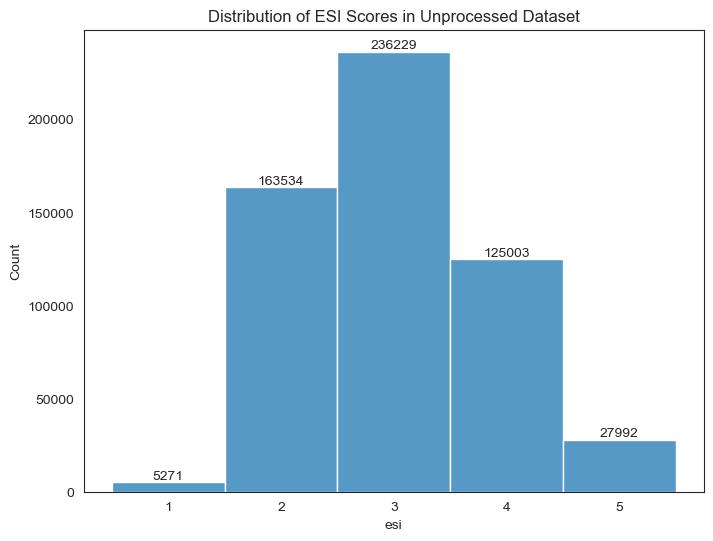

In [6]:
#Histogram of Target feature
plt.figure(figsize=(8,6))
sns.set_style('white')

plot = sns.histplot(data = df, x = 'esi')
plot.bar_label(plot.containers[0]) #add value counts 
plt.title("Distribution of ESI Scores in Unprocessed Dataset")
plt.show()

In [6]:

triageFeatures = ['triage_vital_hr',
                  'triage_vital_sbp','triage_vital_dbp','triage_vital_rr',
                  'triage_vital_o2','triage_vital_o2_device','triage_vital_temp']

In [7]:
df[triageFeatures].describe()
#reviewing number triage value stats

,triage_vital_hr,triage_vital_sbp,triage_vital_dbp,triage_vital_rr,triage_vital_o2,triage_vital_o2_device,triage_vital_temp
count,394434.000000,392582.000000,392423.000000,389999.000000,289169.000000,333631.000000,377501.000000
mean,85.593333,133.365059,80.486044,17.617040,97.266667,0.040599,98.084147
std,16.717428,21.318966,13.867425,1.955679,1.933673,0.197359,0.783628
min,30.000000,45.000000,25.000000,8.000000,60.000000,0.000000,90.000000
25%,74.000000,119.000000,71.000000,16.000000,96.000000,0.000000,97.700000
50%,84.000000,131.000000,80.000000,18.000000,98.000000,0.000000,98.000000
75%,96.000000,145.000000,89.000000,18.000000,99.000000,0.000000,98.400000
max,280.000000,312.000000,214.000000,69.000000,99.000000,1.000000,106.000000


In [8]:
df['arrivalmode'].value_counts()

arrivalmode
Car                      223086
ambulance                190370
Walk-in                  113731
Other                      6914
Public Transportation      2824
Wheelchair                 1578
Police                       99
Name: count, dtype: int64

In [9]:
df['esi'].value_counts()

esi
3    236229
2    163534
4    125003
5     27992
1      5271
Name: count, dtype: int64

In [10]:
df['arrivalhour_bin'].value_counts()

arrivalhour_bin
11-14    145076
15-18    130574
07-10    103336
19-22     99517
23-02     49843
03-06     32140
Name: count, dtype: int64

In [11]:
df['arrivalmonth'].value_counts()

arrivalmonth
May          58030
June         56714
March        56388
April        56016
July         43682
August       43673
January      42749
December     42045
September    41775
October      41638
November     39574
February     38202
Name: count, dtype: int64

In [12]:
df['arrivalday'].value_counts()

arrivalday
Monday       86028
Tuesday      81277
Wednesday    80009
Friday       79294
Thursday     78493
Sunday       77724
Saturday     77661
Name: count, dtype: int64

In [13]:
df['race'].value_counts()

race
White or Caucasian                           299632
Black or African American                    157884
Other                                         89359
Asian                                          5790
Patient Refused                                5203
Unknown                                        1702
American Indian or Alaska Native                515
Native Hawaiian or Other Pacific Islander       375
Name: count, dtype: int64

In [14]:
df['gender'].value_counts()

gender
Female    309653
Male      250833
Name: count, dtype: int64

In [3]:
#past medical history cols
pmh_cols = df.loc[:,'2ndarymalig':'whtblooddx']

#adding prefix to all pmh columns 
df = df.rename(columns={c: 'pmh_'+c for c in df.columns if c in pmh_cols})

#needed to check if patients can have multiple historical conditions
pmh_cols.head() #inspecting pmh cols to find multiple values per row

,2ndarymalig,abdomhernia,abdomnlpain,abortcompl,acqfootdef,acrenlfail,acutecvd,acutemi,acutphanm,adjustmentdisorders,...,ulcerskin,umbilcord,unclassified,urinstone,urinyorgca,uteruscancr,uti,varicosevn,viralinfect,whtblooddx
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
#Reducing the dataset to features representative of the triage process:
#key demographics, chief complaint, triage vitals, past medical conditions,
#past hospital visits, current medications, arrival time / method

#ethnicity is binary latino / non-latino

unwanted_features = [
    'disposition','ethnicity','lang','religion','maritalstatus','employstatus','insurance_status',
    'dep_name','cxr_count','echo_count','ekg_count','headct_count','mri_count','otherct_count',
    'otherimg_count','otherus_count','otherxr_count','pulse_last', 'resp_last', 'spo2_last', 
    'temp_last', 'sbp_last', 'dbp_last', 'o2_device_last', 'pulse_min', 'resp_min', 'spo2_min', 
    'temp_min', 'sbp_min', 'dbp_min', 'o2_device_min', 'pulse_max', 'resp_max', 'spo2_max', 'temp_max', 'sbp_max', 'dbp_max', 
    'o2_device_max', 'pulse_median', 'resp_median', 'spo2_median', 'temp_median', 
    'sbp_median', 'dbp_median', 'o2_device_median', 'absolutelymphocytecount_last', 'acetonebld_last', 
    'alanineaminotransferase(alt)_last', 'albumin_last', 'alkphos_last', 'anc(absneutrophilcount)_last', 'aniongap_last', 
    'aspartateaminotransferase(ast)_last', 'b-typenatriureticpeptide,pro(probnp)_last', 'baseexcess(poc)_last', 'baseexcess,venous(poc)_last', 'basos_last', 
    'basosabs_last', 'benzodiazepinesscreen,urine,noconf._last', 'bilirubindirect_last', 'bilirubintotal_last', 'bun_last', 
    'bun/creatratio_last', 'calcium_last', 'calculatedco2(poc)_last', 'calculatedhco3(poc)i_last', 'calculatedo2saturation(poc)_last', 
    'chloride_last', 'cktotal_last', 'co2_last', 'co2calculated,venous(poc)_last', 'co2,poc_last', 
    'creatinine_last', 'd-dimer_last', 'egfr_last', 'egfr(nonafricanamerican)_last', 'egfr(aframer)_last', 
    'eos_last', 'eosinoabs_last', 'epithelialcells_last', 'globulin_last', 'glucose_last', 
    'glucose,meter_last', 'hco3calculated,venous(poc)_last', 'hematocrit_last', 'hemoglobin_last', 'immaturegrans(abs)_last', 
    'immaturegranulocytes_last', 'inr_last', 'lactate,poc_last', 'lipase_last', 'lymphs_last', 
    'magnesium_last', 'mch_last', 'mchc_last', 'mcv_last', 'monocytes_last', 
    'monosabs_last', 'mpv_last', 'neutrophils_last', 'nrbc_last', 'nrbcabsolute_last', 
    'o2satcalculated,venous(poc)_last', 'pco2(poc)_last', 'pco2,venous(poc)_last', 'ph,venous(poc)_last', 'phencyclidine(pcp)screen,urine,noconf._last', 
    'phosphorus_last', 'platelets_last', 'po2(poc)_last', 'po2,venous(poc)_last', 'pocbun_last', 
    'poccreatinine_last', 'pocglucose_last', 'pochematocrit_last', 'pocionizedcalcium_last', 'pocph_last', 
    'pocpotassium_last', 'pocsodium_last', 'poctroponini._last', 'potassium_last', 'proteintotal_last', 
    'prothrombintime_last', 'ptt_last', 'rbc_last', 'rbc/hpf_last', 'rdw_last', 
    'sodium_last', 'troponini(poc)_last', 'troponint_last', 'tsh_last', 'wbc_last', 
    'wbc/hpf_last', 'absolutelymphocytecount_min', 'acetonebld_min', 'alanineaminotransferase(alt)_min', 'albumin_min', 
    'alkphos_min', 'anc(absneutrophilcount)_min', 'aniongap_min', 'aspartateaminotransferase(ast)_min', 'b-typenatriureticpeptide,pro(probnp)_min', 
    'baseexcess(poc)_min', 'baseexcess,venous(poc)_min', 'basos_min', 'basosabs_min', 'benzodiazepinesscreen,urine,noconf._min', 
    'bilirubindirect_min', 'bilirubintotal_min', 'bun_min', 'bun/creatratio_min', 'calcium_min', 
    'calculatedco2(poc)_min', 'calculatedhco3(poc)i_min', 'calculatedo2saturation(poc)_min', 'chloride_min', 'cktotal_min', 
    'co2_min', 'co2calculated,venous(poc)_min', 'co2,poc_min', 'creatinine_min', 'd-dimer_min', 
    'egfr_min', 'egfr(nonafricanamerican)_min', 'egfr(aframer)_min', 'eos_min', 'eosinoabs_min', 
    'epithelialcells_min', 'globulin_min', 'glucose_min', 'glucose,meter_min', 'hco3calculated,venous(poc)_min', 
    'hematocrit_min', 'hemoglobin_min', 'immaturegrans(abs)_min', 'immaturegranulocytes_min', 'inr_min', 
    'lactate,poc_min', 'lipase_min', 'lymphs_min', 'magnesium_min', 'mch_min', 
    'mchc_min', 'mcv_min', 'monocytes_min', 'monosabs_min', 'mpv_min', 
    'neutrophils_min', 'nrbc_min', 'nrbcabsolute_min', 'o2satcalculated,venous(poc)_min', 'pco2(poc)_min', 
    'pco2,venous(poc)_min', 'ph,venous(poc)_min', 'phencyclidine(pcp)screen,urine,noconf._min', 'phosphorus_min', 'platelets_min', 
    'po2(poc)_min', 'po2,venous(poc)_min', 'pocbun_min', 'poccreatinine_min', 'pocglucose_min', 
    'pochematocrit_min', 'pocionizedcalcium_min', 'pocph_min', 'pocpotassium_min', 'pocsodium_min', 
    'poctroponini._min', 'potassium_min', 'proteintotal_min', 'prothrombintime_min', 'ptt_min', 
    'rbc_min', 'rbc/hpf_min', 'rdw_min', 'sodium_min', 'troponini(poc)_min', 
    'troponint_min', 'tsh_min', 'wbc_min', 'wbc/hpf_min', 'absolutelymphocytecount_max', 
    'acetonebld_max', 'alanineaminotransferase(alt)_max', 'albumin_max', 'alkphos_max', 'anc(absneutrophilcount)_max', 
    'aniongap_max', 'aspartateaminotransferase(ast)_max', 'b-typenatriureticpeptide,pro(probnp)_max', 'baseexcess(poc)_max', 'baseexcess,venous(poc)_max', 
    'basos_max', 'basosabs_max', 'benzodiazepinesscreen,urine,noconf._max', 'bilirubindirect_max', 'bilirubintotal_max', 
    'bun_max', 'bun/creatratio_max', 'calcium_max', 'calculatedco2(poc)_max', 'calculatedhco3(poc)i_max', 
    'calculatedo2saturation(poc)_max', 'chloride_max', 'cktotal_max', 'co2_max', 'co2calculated,venous(poc)_max', 
    'co2,poc_max', 'creatinine_max', 'd-dimer_max', 'egfr_max', 'egfr(nonafricanamerican)_max', 
    'egfr(aframer)_max', 'eos_max', 'eosinoabs_max', 'epithelialcells_max', 'globulin_max', 
    'glucose_max', 'glucose,meter_max', 'hco3calculated,venous(poc)_max', 'hematocrit_max', 'hemoglobin_max', 
    'immaturegrans(abs)_max', 'immaturegranulocytes_max', 'inr_max', 'lactate,poc_max', 'lipase_max', 
    'lymphs_max', 'magnesium_max', 'mch_max', 'mchc_max', 'mcv_max', 
    'monocytes_max', 'monosabs_max', 'mpv_max', 'neutrophils_max', 'nrbc_max', 
    'nrbcabsolute_max', 'o2satcalculated,venous(poc)_max', 'pco2(poc)_max', 'pco2,venous(poc)_max', 'ph,venous(poc)_max', 
    'phencyclidine(pcp)screen,urine,noconf._max', 'phosphorus_max', 'platelets_max', 'po2(poc)_max', 'po2,venous(poc)_max', 
    'pocbun_max', 'poccreatinine_max', 'pocglucose_max', 'pochematocrit_max', 'pocionizedcalcium_max', 
    'pocph_max', 'pocpotassium_max', 'pocsodium_max', 'poctroponini._max', 'potassium_max', 
    'proteintotal_max', 'prothrombintime_max', 'ptt_max', 'rbc_max', 'rbc/hpf_max', 
    'rdw_max', 'sodium_max', 'troponini(poc)_max', 'troponint_max', 'tsh_max', 
    'wbc_max', 'wbc/hpf_max', 'absolutelymphocytecount_median', 'acetonebld_median', 'alanineaminotransferase(alt)_median', 
    'albumin_median', 'alkphos_median', 'anc(absneutrophilcount)_median', 'aniongap_median', 'aspartateaminotransferase(ast)_median', 
    'b-typenatriureticpeptide,pro(probnp)_median', 'baseexcess(poc)_median', 'baseexcess,venous(poc)_median', 'basos_median', 'basosabs_median', 
    'benzodiazepinesscreen,urine,noconf._median', 'bilirubindirect_median', 'bilirubintotal_median', 'bun_median', 'bun/creatratio_median', 
    'calcium_median', 'calculatedco2(poc)_median', 'calculatedhco3(poc)i_median', 'calculatedo2saturation(poc)_median', 'chloride_median', 
    'cktotal_median', 'co2_median', 'co2calculated,venous(poc)_median', 'co2,poc_median', 'creatinine_median', 
    'd-dimer_median', 'egfr_median', 'egfr(nonafricanamerican)_median', 'egfr(aframer)_median', 'eos_median', 
    'eosinoabs_median', 'epithelialcells_median', 'globulin_median', 'glucose_median', 'glucose,meter_median', 
    'hco3calculated,venous(poc)_median', 'hematocrit_median', 'hemoglobin_median', 'immaturegrans(abs)_median', 'immaturegranulocytes_median', 
    'inr_median', 'lactate,poc_median', 'lipase_median', 'lymphs_median', 'magnesium_median', 
    'mch_median', 'mchc_median', 'mcv_median', 'monocytes_median', 'monosabs_median', 
    'mpv_median', 'neutrophils_median', 'nrbc_median', 'nrbcabsolute_median', 'o2satcalculated,venous(poc)_median', 
    'pco2(poc)_median', 'pco2,venous(poc)_median', 'ph,venous(poc)_median', 'phencyclidine(pcp)screen,urine,noconf._median', 'phosphorus_median', 
    'platelets_median', 'po2(poc)_median', 'po2,venous(poc)_median', 'pocbun_median', 'poccreatinine_median', 
    'pocglucose_median', 'pochematocrit_median', 'pocionizedcalcium_median', 'pocph_median', 'pocpotassium_median', 
    'pocsodium_median', 'poctroponini._median', 'potassium_median', 'proteintotal_median', 'prothrombintime_median', 
    'ptt_median', 'rbc_median', 'rbc/hpf_median', 'rdw_median', 'sodium_median', 
    'troponini(poc)_median', 'troponint_median', 'tsh_median', 'wbc_median', 'wbc/hpf_median', 
    'bloodua_last', 'glucoseua_last', 'ketonesua_last', 'leukocytesua_last', 'nitriteua_last', 
    'pregtestur_last', 'proteinua_last', 'bloodculture,routine_last', 'urineculture,routine_last', 'bloodua_npos', 
    'glucoseua_npos', 'ketonesua_npos', 'leukocytesua_npos', 'nitriteua_npos', 'pregtestur_npos', 
    'proteinua_npos', 'bloodculture,routine_npos', 'urineculture,routine_npos', 'bloodua_count', 'glucoseua_count', 
    'ketonesua_count', 'leukocytesua_count', 'nitriteua_count', 'pregtestur_count', 'proteinua_count', 
    'bloodculture,routine_count', 'urineculture,routine_count'
]
triage_df = df.drop(columns=unwanted_features)

In [17]:
triage_df.shape

(560486, 548)

In [5]:
cc_cols = triage_df.filter(like="cc_") #all chief complaint cols with prefix cc_

triage_df['chief_complaint'] = cc_cols.idxmax(axis=1).str.replace('cc_','') 
#get complaint name and strip cc_

#check row-wise max and sum of CC_ values
cc_max = cc_cols.max(axis = 1)
cc_sums = cc_cols.sum(axis = 1)

#if value is 2 prepend severe_, chief_complaint value becomes severe_value
triage_df.loc[cc_max == 2,'chief_complaint'] = 'severe_'+ triage_df.loc[cc_max == 2, 'chief_complaint']

triage_df.loc[cc_sums == 0, 'chief_complaint'] = float('nan')
#if sum of all CC cols is 0, then replace with NaN

C:\Users\paddy\AppData\Local\Temp\ipykernel_18224\2446014523.py:3: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  triage_df['chief_complaint'] = cc_cols.idxmax(axis=1).str.replace('cc_','')


In [ ]:
triage_df['chief_complaint'].value_counts()

chief_complaint
abdominalpain                                  54263
other                                          41587
chestpain                                      33791
backpain                                       19759
shortnessofbreath                              19447
fall                                           16839
alcoholintoxication                            15648
motorvehiclecrash                              13618
dizziness                                      11547
cough                                          11242
legpain                                         8448
alteredmentalstatus                             8403
emesis                                          8178
flankpain                                       8147
headache-newonsetornewsymptoms                  6867
fall>65                                         6862
suicidal                                        5769
psychiatricevaluation                           5763
kneepain                      

In [12]:
#remove original cc_ columns
triage_df = triage_df.drop(columns=df.filter(like="cc_").columns)

In [117]:
#check datatypes
triage_df.dtypes

esi                                                   category
age                                                     object
gender                                                category
race                                                  category
arrivalmode                                           category
arrivalmonth                                          category
arrivalday                                            category
arrivalhour_bin                                       category
previousdispo                                         category
pmh_2ndarymalig                                        float64
pmh_abdomhernia                                        float64
pmh_abdomnlpain                                        float64
pmh_abortcompl                                         float64
pmh_acqfootdef                                         float64
pmh_acrenlfail                                         float64
pmh_acutecvd                                           

In [118]:
#check for Null values
missingCount = triage_df.isna().sum()
print(missingCount)

esi                                                     2457
age                                                       11
gender                                                     0
race                                                      26
arrivalmode                                            21884
arrivalmonth                                               0
arrivalday                                                 0
arrivalhour_bin                                            0
previousdispo                                              0
pmh_2ndarymalig                                            0
pmh_abdomhernia                                            0
pmh_abdomnlpain                                            0
pmh_abortcompl                                             0
pmh_acqfootdef                                             0
pmh_acrenlfail                                             0
pmh_acutecvd                                               0
pmh_acutemi             

In [6]:
#Removing Simple Null values

#Rows with Null ESI, Chief Complaint, age or race are removed
#esi and chief complaint are vital for prediction, age only has 11 rows missing
triage_df = triage_df.dropna(subset=['esi','chief_complaint','age'])

#Null values for arrivalmode are changed to "other"
triage_df['arrivalmode'] = triage_df['arrivalmode'].fillna(value = 'Other')

#Null values for triage_vital_o2_device replaced with 0
#feature is binary for whether the patient has their own o2 device at triage or not
#so null values replaced with no device 
triage_df['triage_vital_o2_device'] = triage_df['triage_vital_o2_device'].fillna(value = 0)

In [7]:
#converting column types
#age from object to int
triage_df['age'] = triage_df['age'].astype('int')

arrivalHR_order = ['23-02','03-06','07-10',
                   '11-14','15-18','19-22']
#arrival hour  categorised in order
triage_df['arrivalhour_bin'] = pd.Categorical(triage_df['arrivalhour_bin'], 
                                              categories = arrivalHR_order, ordered=True)

month_order = ['January', 'February','March','April','May',
              'June','July','August','September','October',
              'November','December']
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday',
            'Saturday','Sunday']

triage_df['arrivalmonth'] = pd.Categorical(triage_df['arrivalmonth'],
                                           categories=month_order, ordered = True)
triage_df['arrivalday'] = pd.Categorical(triage_df['arrivalday'],
                                           categories=day_order, ordered = True)

In [8]:
#renaming categorical features:

triage_df['race'] = triage_df['race'].replace({'American Indian or Alaska Native' : 'Native American',
                                               'Black or African American' : 'Black',
                                               'Native Hawaiian or Other Pacific Islander' : 'Pacific Islander',
                                               'White or Caucasian' : 'White'})

triage_df['arrivalmode'] = triage_df['arrivalmode'].replace({'Public Transportation' : 'Public Transport'})

#These chief complaints are only diferentiated by age
triage_df['chief_complaint'] = triage_df['chief_complaint'].replace({'fall>65' : 'fall',
                                                                     'fever-75yearsorolder' : 'fever',
                                                                     'fever-9weeksto74years' : 'fever'})

C:\Users\paddy\AppData\Local\Temp\ipykernel_18224\1959114928.py:3: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  triage_df['race'] = triage_df['race'].replace({'American Indian or Alaska Native' : 'Native American',
C:\Users\paddy\AppData\Local\Temp\ipykernel_18224\1959114928.py:8: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  triage_df['arrivalmode'] = triage_df['arrivalmode'].replace({'Public Transportation' : 'Public Transport'})


## 2. Feature Distribution and Trend Plots

### ESI and Demographic Plots

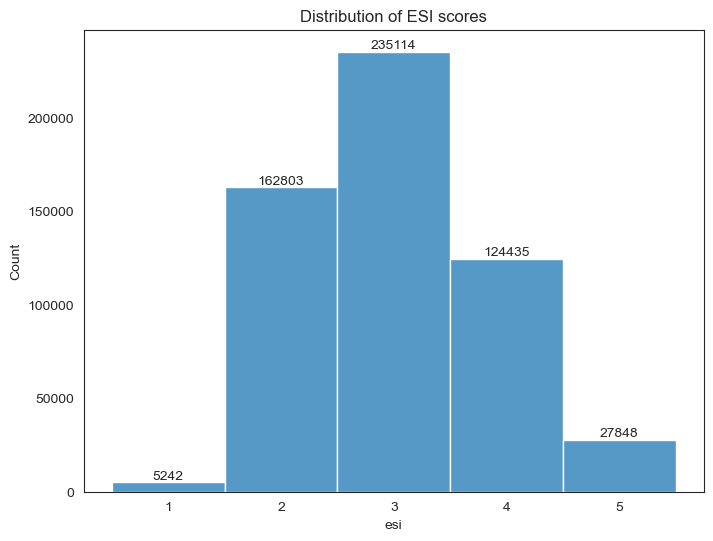

In [16]:
#Histogram of Target feature
plt.figure(figsize=(8,6))
sns.set_style('white')

plot = sns.histplot(data = triage_df, x = 'esi')
plot.bar_label(plot.containers[0]) #add value counts 
plt.title("Distribution of ESI scores")
plt.show()

Fairly Normal distribution 

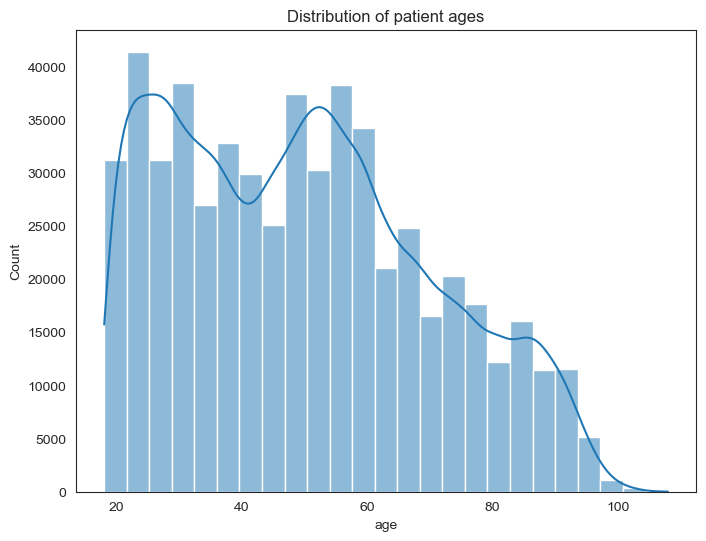

In [123]:
plt.figure(figsize=(8,6))
sns.set_style('white')

sns.histplot(data = triage_df, x = 'age', kde = True, bins = 25)
plt.title("Distribution of patient ages")
plt.show()

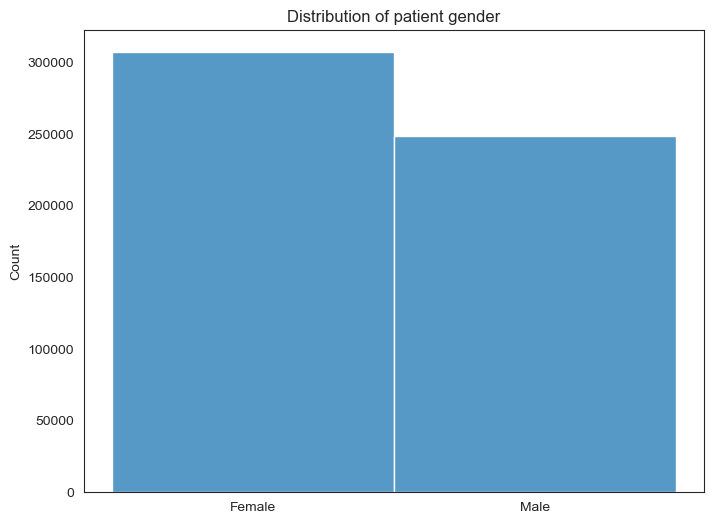

In [124]:
plt.figure(figsize=(8,6))
sns.set_style('white')

sns.histplot(data = triage_df, x = 'gender')
plt.title("Distribution of patient gender")
plt.xlabel('')
plt.show()

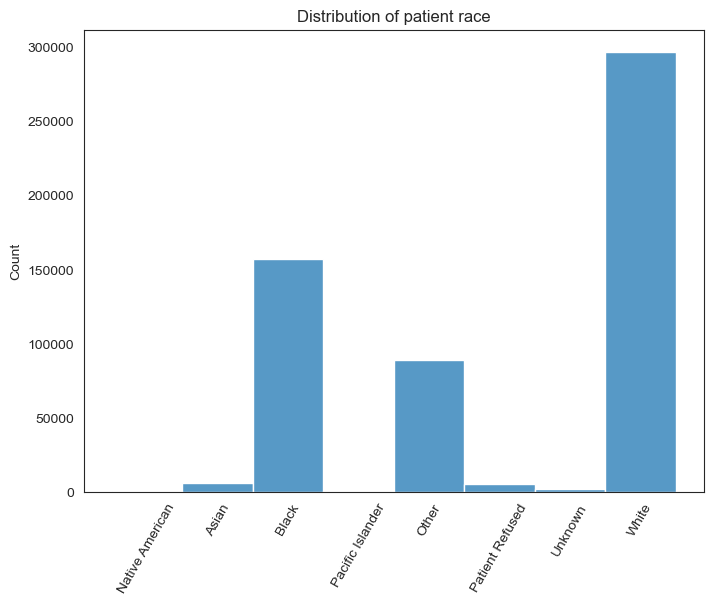

In [125]:
plt.figure(figsize=(8,6))
sns.set_style('white')

sns.histplot(data = triage_df, x = 'race')
plt.title("Distribution of patient race")
plt.xticks(rotation=60)
plt.xlabel('')
plt.show()

### Patient Arrival Features plots

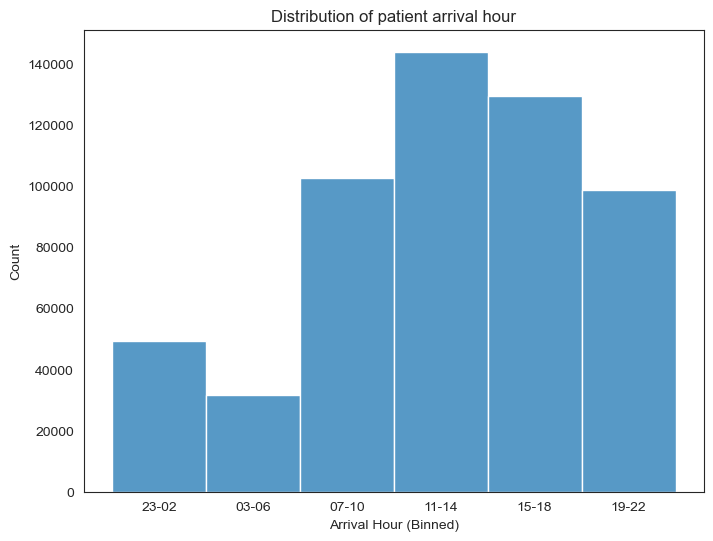

In [126]:
plt.figure(figsize=(8,6))
sns.set_style('white')

sns.histplot(data = triage_df, x = 'arrivalhour_bin')
plt.title("Distribution of patient arrival hour")
plt.xlabel('Arrival Hour (Binned)')
plt.show()

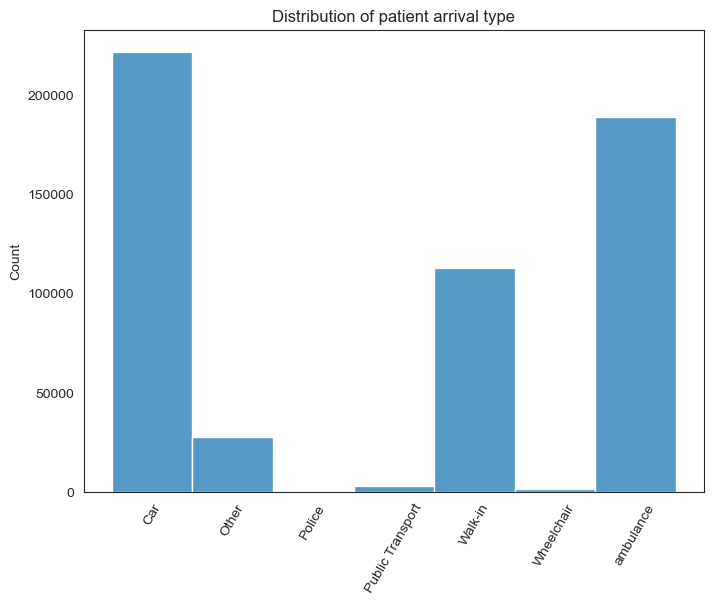

In [127]:
plt.figure(figsize=(8,6))
sns.set_style('white')

sns.histplot(data = triage_df, x = 'arrivalmode')
plt.title("Distribution of patient arrival type")
plt.xticks(rotation=60)
plt.xlabel('')
plt.show()

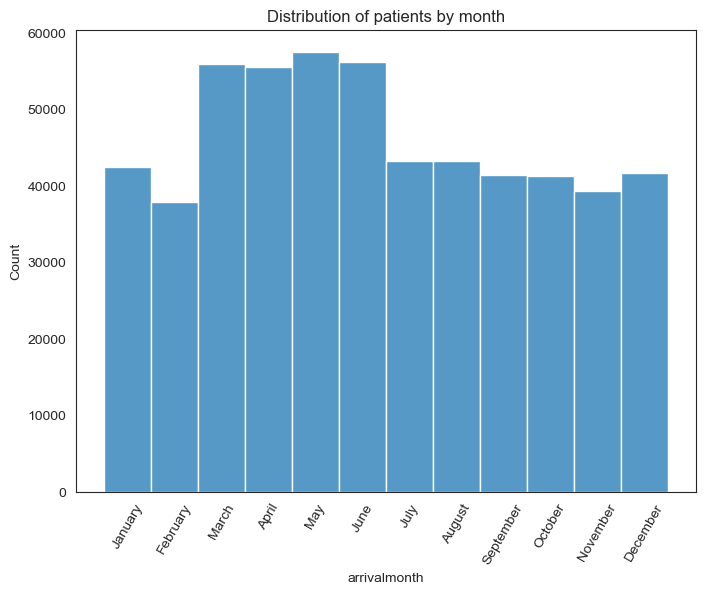

In [128]:
plt.figure(figsize=(8,6))
sns.set_style('white')

sns.histplot(data = triage_df, x = 'arrivalmonth')
plt.title("Distribution of patients by month")
plt.xticks(rotation=60)
plt.show()

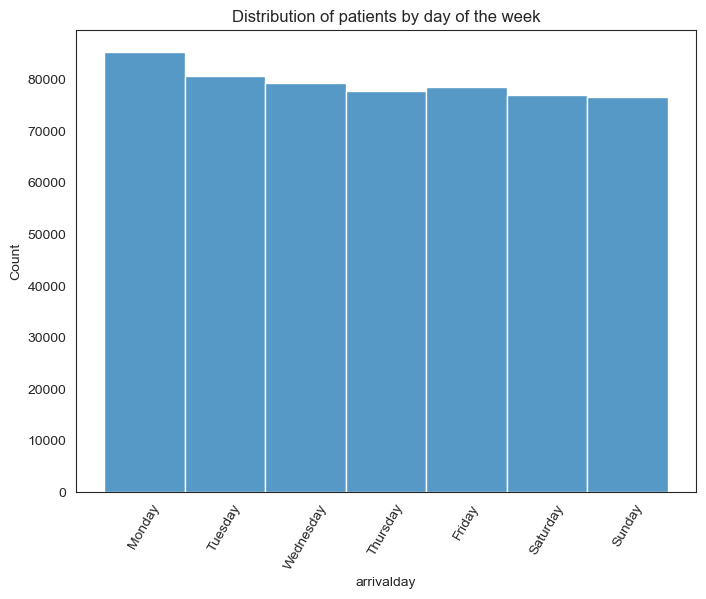

In [129]:
plt.figure(figsize=(8,6))
sns.set_style('white')

sns.histplot(data = triage_df, x = 'arrivalday')
plt.title("Distribution of patients by day of the week")
plt.xticks(rotation=60)
plt.show()

### Combined Distribution Plots

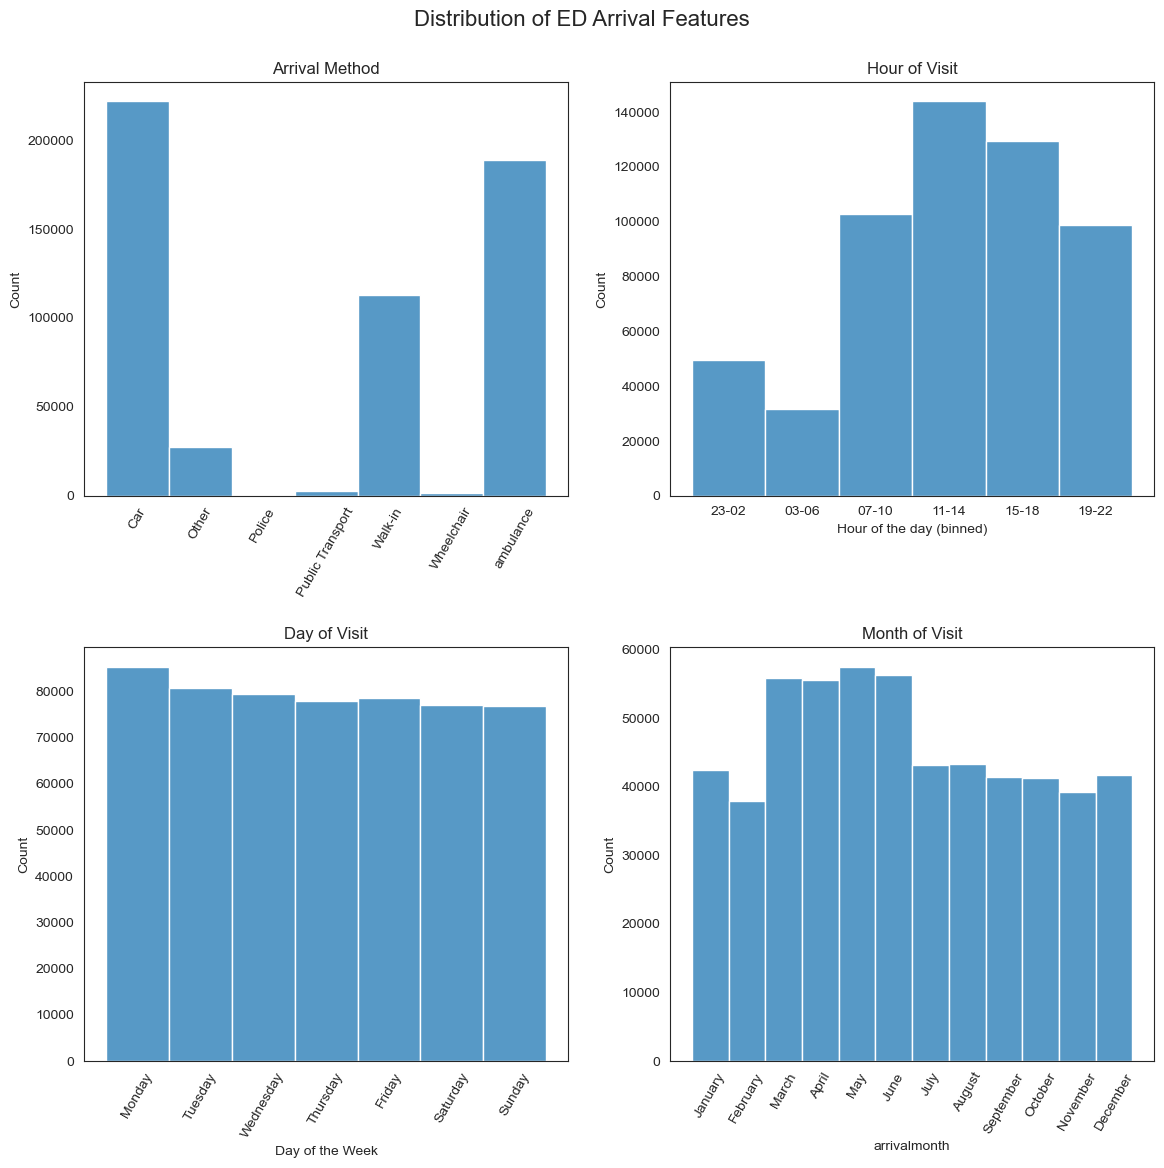

In [130]:
fig, axes = plt.subplots(2,2, figsize = (12,12))
sns.set_style('white')
plot1 = axes[0,0]
plot2 = axes[0,1]
plot3 = axes[1,0]
plot4 = axes[1,1]

sns.histplot(data = triage_df, x = 'arrivalmode', ax = plot1)
plot1.set_title("Arrival Method")
plot1.tick_params('x', rotation = 60)
plot1.set_xlabel('')

sns.histplot(data = triage_df, x = 'arrivalhour_bin', ax = plot2)
plot2.set_title("Hour of Visit")
plot2.set_xlabel("Hour of the day (binned)")

sns.histplot(data = triage_df, x = 'arrivalday', ax = plot3)
plot3.set_title("Day of Visit")
plot3.tick_params('x', rotation = 60)
plot3.set_xlabel("Day of the Week")

sns.histplot(data = triage_df, x = 'arrivalmonth', ax = plot4)
plot4.set_title("Month of Visit")
plot4.tick_params('x', rotation = 60)
plot1.set_xlabel('')


plt.suptitle("Distribution of ED Arrival Features", fontsize =16)
plt.tight_layout(pad=2.0)
plt.show()


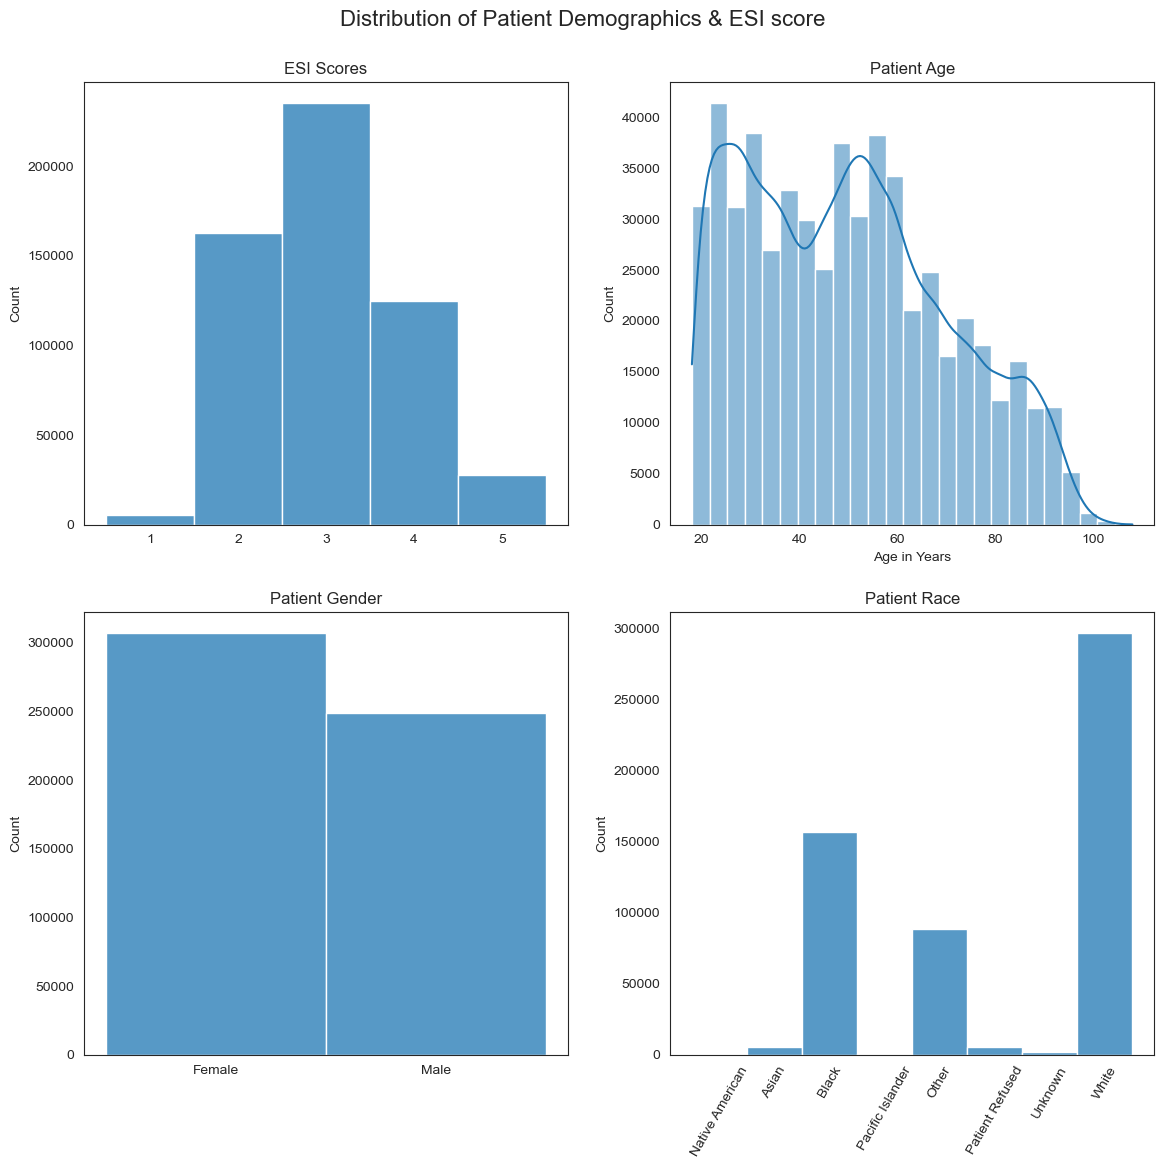

In [131]:
fig, axes = plt.subplots(2,2, figsize = (12,12))
sns.set_style('white')
plot1 = axes[0,0]
plot2 = axes[0,1]
plot3 = axes[1,0]
plot4 = axes[1,1]

sns.histplot(data = triage_df, x = 'esi', ax = plot1)
plot1.set_title("ESI Scores")
plot1.set_xlabel('')

sns.histplot(data = triage_df, x = 'age', kde = True, bins = 25, ax = plot2)
plot2.set_title("Patient Age")
plot2.set_xlabel("Age in Years")

sns.histplot(data = triage_df, x = 'gender', ax = plot3)
plot3.set_title("Patient Gender")
plot3.set_xlabel('')

sns.histplot(data = triage_df, x = 'race', ax = plot4)
plot4.set_title("Patient Race")
plot4.tick_params('x', rotation = 60)
plot4.set_xlabel('')


plt.suptitle("Distribution of Patient Demographics & ESI score", fontsize =16)
plt.tight_layout(pad=2.0)
plt.show()

### Features vs ESI score plots

In [15]:
#Creating a categorical representation of patient age
def ageGroup(x):
    if (x > 15 and x < 21):
        return "16-20"
    if (x > 20 and x < 26):
        return "21-25"
    if (x > 25 and x < 31):
        return "26-30"
    if (x > 30 and x < 36):
        return "31-35"
    if (x > 35 and x < 41):
        return "36-40"
    if (x > 40 and x < 46):
        return "41-45"
    if (x > 45 and x < 51):
        return "46-50"
    if (x > 50 and x < 56):
        return "51-55"
    if (x > 55 and x < 61):
        return "56-60"
    if (x > 60 and x < 66):
        return "61-65"
    if (x > 65 and x < 71):
        return "65-70"
    if (x > 70 and x < 76):
        return "71-75"
    if (x > 75 and x < 81):
        return "76-80"
    else:
        return "80+"

triage_df['ageGroup'] = triage_df['age'].apply(ageGroup)

In [16]:
colours = ['lightblue','darkorange','navy','brown','green']

def contingencyTablePlot(feature1, feature2, plotnum, title):
    
    contingencyTable = pd.crosstab(triage_df[feature1], triage_df[feature2], normalize='index')
    contingencyTable.plot(kind = 'bar', stacked = True, color = colours, ax =plotnum)
    plotnum.set_title(title)
    plotnum.set_xlabel('')
    plotnum.set_ylabel("Proportion of records")
    plotnum.get_legend().remove()

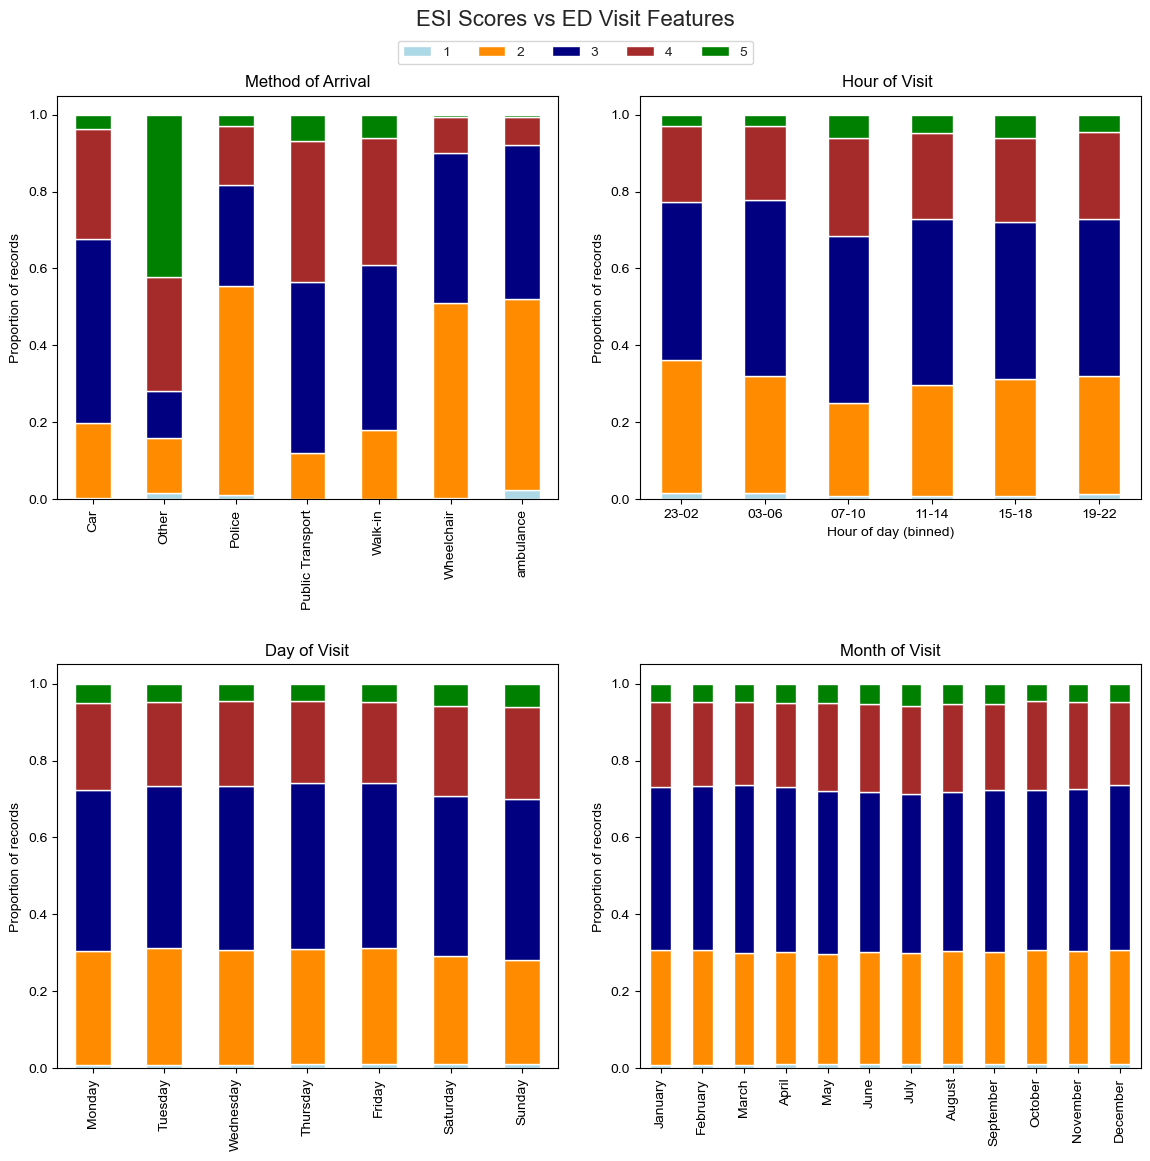

In [17]:
fig, axes = plt.subplots(2,2, figsize = (12,12))
sns.set_style('white')
plot1 = axes[0,0]
plot2 = axes[0,1]
plot3 = axes[1,0]
plot4 = axes[1,1]

contingencyTablePlot('arrivalmode','esi',plot1,"Method of Arrival")
contingencyTablePlot('arrivalhour_bin','esi',plot2,"Hour of Visit ")
contingencyTablePlot('arrivalday','esi',plot3,"Day of Visit")
contingencyTablePlot('arrivalmonth','esi',plot4,"Month of Visit")

#correcting plot 2 x labels
plot2.tick_params('x',rotation=0)
plot2.set_xlabel("Hour of day (binned)")

#legend formatting
handles, labels = plot1.get_legend_handles_labels()
fig.legend(handles, labels, loc = 'upper center', 
           ncol = len(handles), bbox_to_anchor=(0.5, 0.96))


plt.suptitle("ESI Scores vs ED Visit Features", fontsize = 16)
plt.tight_layout(pad=2.5)
plt.show()

Only real variance of note is with arrival method.

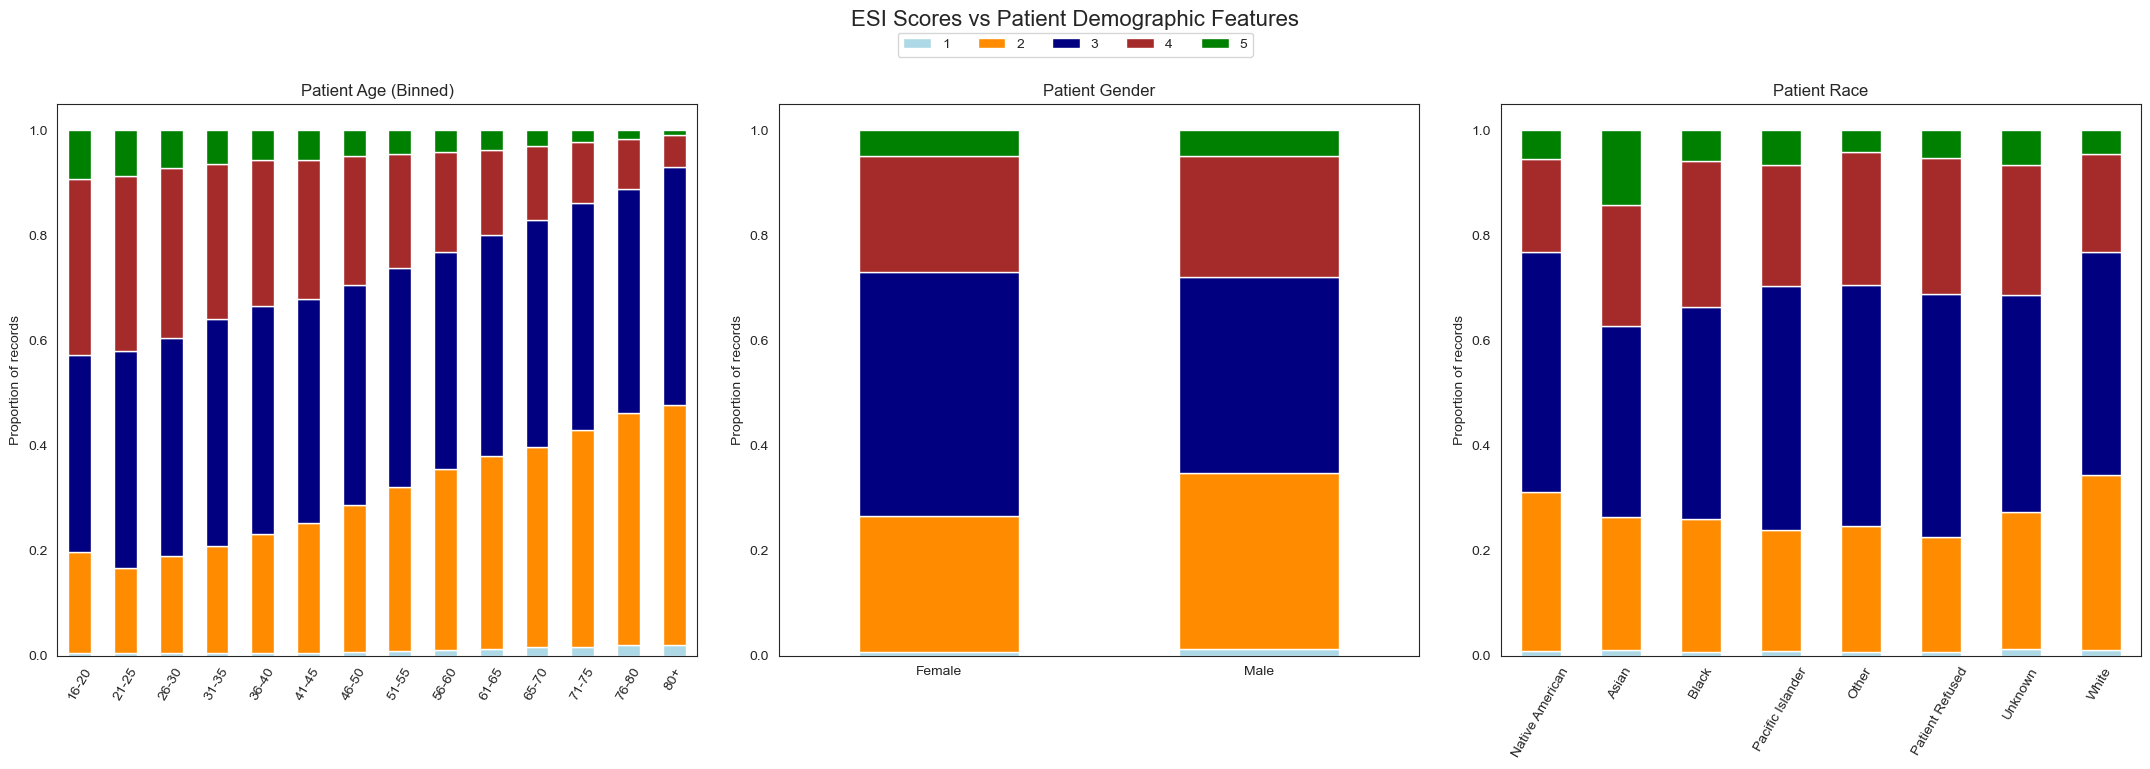

In [18]:
fig, axes = plt.subplots(1,3, figsize = (22,8))
sns.set_style('white')
plot1 = axes[0]
plot2 = axes[1]
plot3 = axes[2]


contingencyTablePlot('ageGroup','esi',plot1,"Patient Age (Binned)")
contingencyTablePlot('gender','esi',plot2,"Patient Gender")
contingencyTablePlot('race','esi',plot3,"Patient Race")
#contingencyTablePlot('arrivalmonth','esi',plot4,"Month of Visit")

#Correcting X labels
plot1.tick_params('x',rotation=60)
plot2.tick_params('x',rotation=0)
plot3.tick_params('x',rotation=60)

handles, labels = plot1.get_legend_handles_labels()
fig.legend(handles, labels, loc = 'upper center', 
           ncol = len(handles), bbox_to_anchor=(0.5, 0.96))
plt.suptitle("ESI Scores vs Patient Demographic Features", fontsize = 16)
plt.tight_layout(pad=2.5)
plt.show()

Age shows the strongest correlation to ESI, with older patients frequently having higher esi scores. greater proportion of men with ESI 1 and 2 than women

## 3. Null Triage Vitals Imputation

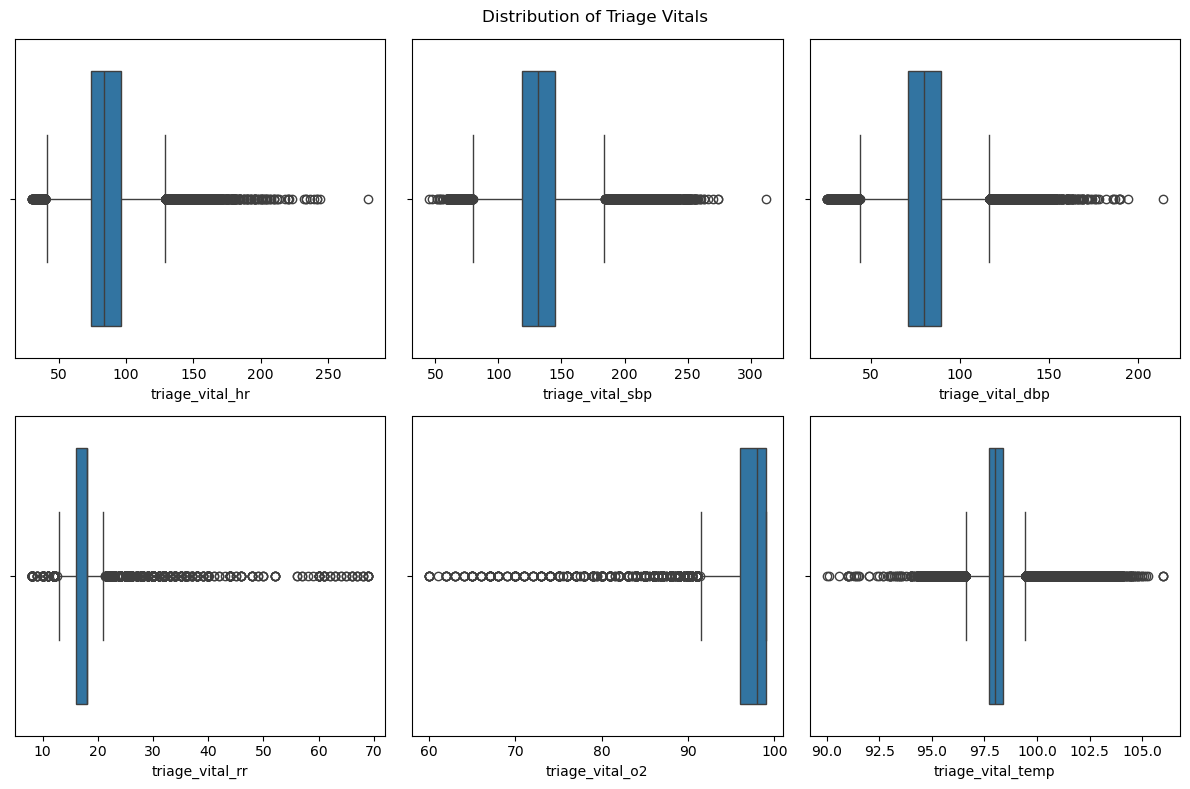

In [9]:
fig,axes = plt.subplots(2,3, figsize = (12,8))

sns.boxplot(data = triage_df, x = 'triage_vital_hr', ax = axes[0,0])
sns.boxplot(data = triage_df, x = 'triage_vital_sbp', ax = axes[0,1])
sns.boxplot(data = triage_df, x = 'triage_vital_dbp', ax = axes[0,2])
sns.boxplot(data = triage_df, x = 'triage_vital_rr', ax = axes[1,0])
sns.boxplot(data = triage_df, x = 'triage_vital_o2', ax = axes[1,1])
sns.boxplot(data = triage_df, x = 'triage_vital_temp', ax = axes[1,2])

plt.suptitle("Distribution of Triage Vitals")
plt.tight_layout()
plt.show()

In [10]:
triage_vitals = ['triage_vital_hr','triage_vital_sbp',
                'triage_vital_dbp','triage_vital_rr',
                'triage_vital_o2','triage_vital_o2_device','triage_vital_temp']
triage_df[triage_vitals].describe()

,triage_vital_hr,triage_vital_sbp,triage_vital_dbp,triage_vital_rr,triage_vital_o2,triage_vital_o2_device,triage_vital_temp
count,391938.000000,390101.000000,389942.000000,387560.000000,287298.000000,555442.000000,375138.000000
mean,85.592843,133.371256,80.489443,17.616637,97.267569,0.024210,98.084242
std,16.715195,21.318278,13.863827,1.954165,1.933788,0.153699,0.783532
min,30.000000,45.000000,25.000000,8.000000,60.000000,0.000000,90.000000
25%,74.000000,119.000000,71.000000,16.000000,96.000000,0.000000,97.700000
50%,84.000000,131.000000,80.000000,18.000000,98.000000,0.000000,98.000000
75%,96.000000,145.000000,89.000000,18.000000,99.000000,0.000000,98.400000
max,280.000000,312.000000,214.000000,69.000000,99.000000,1.000000,106.000000


In [11]:
#Largest vital outliers:
#all appear to be true patient vitals:
high_hr = triage_df.loc[triage_df['triage_vital_hr'] > 250] #cc_rapidheartrate ESI 1
high_sbp = triage_df.loc[triage_df['triage_vital_sbp'] > 300] #cc_shortnessofbreath ESI 2
high_dbp = triage_df.loc[triage_df['triage_vital_dbp'] > 200] #cc_shortnessofbreath ESI 2
high_temp = triage_df.loc[triage_df['triage_vital_temp'] > 105.5] #3 patients ESI 2 and 1

high_hr
#high_sbp
#high_dbp
#high_temp


,esi,age,gender,race,arrivalmode,arrivalmonth,arrivalday,arrivalhour_bin,previousdispo,pmh_2ndarymalig,...,cc_vaginalpain,cc_weakness,cc_wheezing,cc_withdrawal-alcohol,cc_woundcheck,cc_woundinfection,cc_woundre-evaluation,cc_wristinjury,cc_wristpain,chief_complaint
521809,1,67,Male,White,Other,June,Sunday,23-02,Admit,0.0,...,0,0,0,0,0,0,0,0,0,rapidheartrate


At this point the only features remaining with null values are triage vitals: Heart rate, systolic and diasystolic blood pressure, respiration rate and temperature. 

The following rules will be applied to these null values:
- If more than 2 values are null the row is removed (not enough signal and therefore too noisy)
- Under 2 Null values, move to imputation

KNN imputation seems to be best for this situation. Can look at other similar patients to determine missing values using the mean of K-neighbours

In [12]:
#Baseline Null value check
missingCount = triage_df[triage_vitals].isna().sum()
print(missingCount)

triage_vital_hr           163504
triage_vital_sbp          165341
triage_vital_dbp          165500
triage_vital_rr           167882
triage_vital_o2           268144
triage_vital_o2_device         0
triage_vital_temp         180304
dtype: int64


In [13]:
#Creating dataset subsets for imputation
#subset  - just ESI, age, vitals
subset_df = triage_df[['esi','age','triage_vital_hr',
                          'triage_vital_sbp','triage_vital_dbp',
                          'triage_vital_rr','triage_vital_o2',
                          'triage_vital_o2_device','triage_vital_temp']]

In [14]:
#drop rows with more than 2 missing vitals i.e. keep rows with 4 out of possible 6 remaining
triage_df_cleaned = subset_df.dropna(subset=triage_vitals, thresh=4).copy()

#Recheck Null values for vitals
missingCount = triage_df_cleaned[triage_vitals].isna().sum()
print(missingCount)

triage_vital_hr              806
triage_vital_sbp            2490
triage_vital_dbp            2648
triage_vital_rr             5127
triage_vital_o2           105407
triage_vital_o2_device         0
triage_vital_temp          17574
dtype: int64


### Imputation using subset 

In [15]:

#scaling features in range of 0-1
scaler = MinMaxScaler()
features_scaled = scaler.fit_transform(triage_df_cleaned)

#declare KNN imputer and hyperparams
imputer = KNNImputer(
    n_neighbors= 5,
    weights='distance'
)

#fit to impute missing triage vitals
#imputes values using the mean of nearest neighbours
imputed_vitals = imputer.fit_transform(features_scaled)

#Inverse scaling to return to original features
imputed_vitals = scaler.inverse_transform(imputed_vitals)

#Replace missing vitals with imputed vitals
triage_df_cleaned[triage_vitals] = imputed_vitals[:, 2:]

c:\Users\paddy\anaconda3\Lib\site-packages\numpy\_core\fromnumeric.py:86: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
c:\Users\paddy\anaconda3\Lib\site-packages\numpy\_core\fromnumeric.py:86: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
c:\Users\paddy\anaconda3\Lib\site-packages\sklearn\preprocessing\_data.py:542: RuntimeWarning: invalid value encountered in multiply
  X *= self.scale_


In [ ]:
#Recheck Null values for vitals to confirm imputation
missingCount = triage_df_cleaned.isna().sum()
print(missingCount)

esi                       0
age                       0
triage_vital_hr           0
triage_vital_sbp          0
triage_vital_dbp          0
triage_vital_rr           0
triage_vital_o2           0
triage_vital_o2_device    0
triage_vital_temp         0
dtype: int64


In [16]:
#with imputed values
triage_df_cleaned[triage_vitals].describe()

,triage_vital_hr,triage_vital_sbp,triage_vital_dbp,triage_vital_rr,triage_vital_o2,triage_vital_o2_device,triage_vital_temp
count,392430.000000,392430.000000,392430.000000,392430.000000,392430.000000,392430.000000,392430.000000
mean,85.580197,133.384482,80.494095,17.618183,97.326779,0.034093,98.082930
std,16.685556,21.278994,13.838952,1.943380,1.727735,0.181468,0.771879
min,30.000000,45.000000,25.000000,8.000000,60.000000,0.000000,90.000000
25%,74.000000,119.000000,71.000000,16.000000,97.000000,0.000000,97.700000
50%,84.000000,131.000000,80.000000,18.000000,97.992178,0.000000,98.000000
75%,96.000000,145.000000,89.000000,18.000000,98.173229,0.000000,98.400000
max,280.000000,312.000000,214.000000,69.000000,99.000000,1.000000,106.000000


In [17]:
#original values
triage_df[triage_vitals].describe()

,triage_vital_hr,triage_vital_sbp,triage_vital_dbp,triage_vital_rr,triage_vital_o2,triage_vital_o2_device,triage_vital_temp
count,391938.000000,390101.000000,389942.000000,387560.000000,287298.000000,555442.000000,375138.000000
mean,85.592843,133.371256,80.489443,17.616637,97.267569,0.024210,98.084242
std,16.715195,21.318278,13.863827,1.954165,1.933788,0.153699,0.783532
min,30.000000,45.000000,25.000000,8.000000,60.000000,0.000000,90.000000
25%,74.000000,119.000000,71.000000,16.000000,96.000000,0.000000,97.700000
50%,84.000000,131.000000,80.000000,18.000000,98.000000,0.000000,98.000000
75%,96.000000,145.000000,89.000000,18.000000,99.000000,0.000000,98.400000
max,280.000000,312.000000,214.000000,69.000000,99.000000,1.000000,106.000000


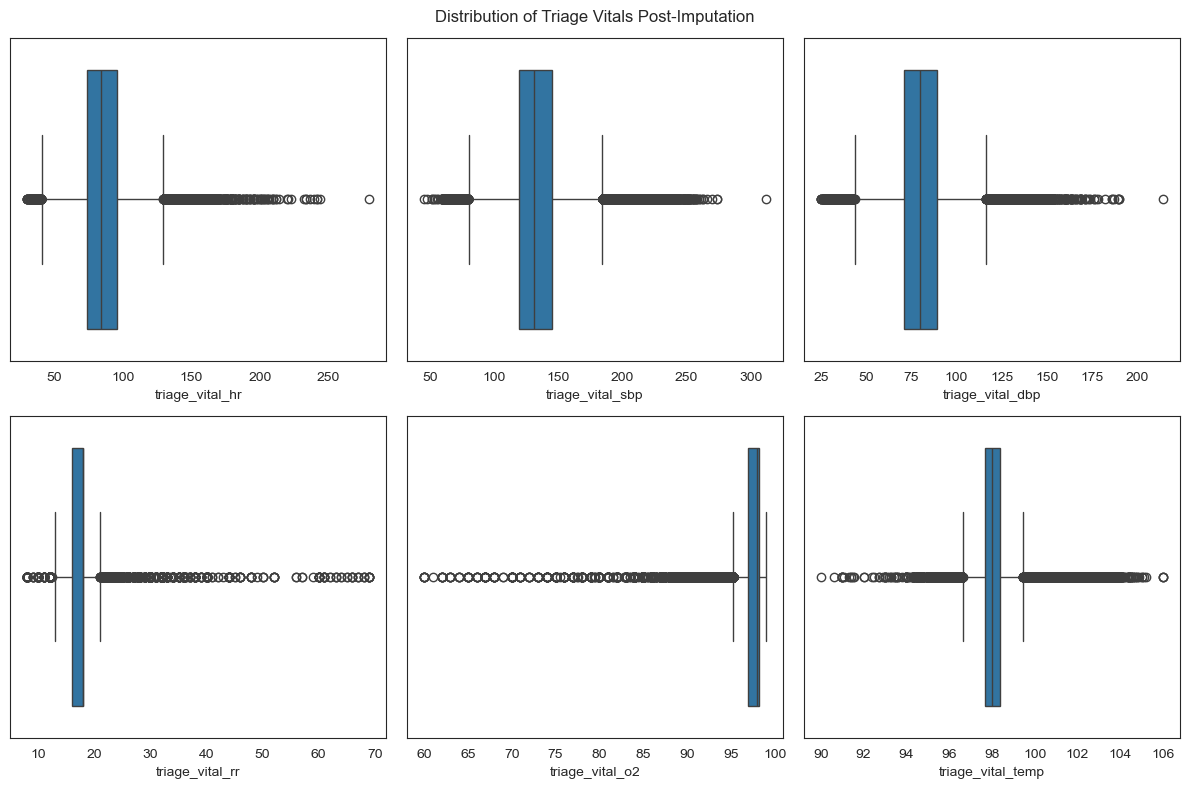

In [ ]:
#imputed values
fig,axes = plt.subplots(2,3, figsize = (12,8))

sns.boxplot(data = triage_df_cleaned, x = 'triage_vital_hr', ax = axes[0,0])
sns.boxplot(data = triage_df_cleaned, x = 'triage_vital_sbp', ax = axes[0,1])
sns.boxplot(data = triage_df_cleaned, x = 'triage_vital_dbp', ax = axes[0,2])
sns.boxplot(data = triage_df_cleaned, x = 'triage_vital_rr', ax = axes[1,0])
sns.boxplot(data = triage_df_cleaned, x = 'triage_vital_o2', ax = axes[1,1])
sns.boxplot(data = triage_df_cleaned, x = 'triage_vital_temp', ax = axes[1,2])

plt.suptitle("Distribution of Triage Vitals Post-Imputation")
plt.tight_layout()
plt.show()

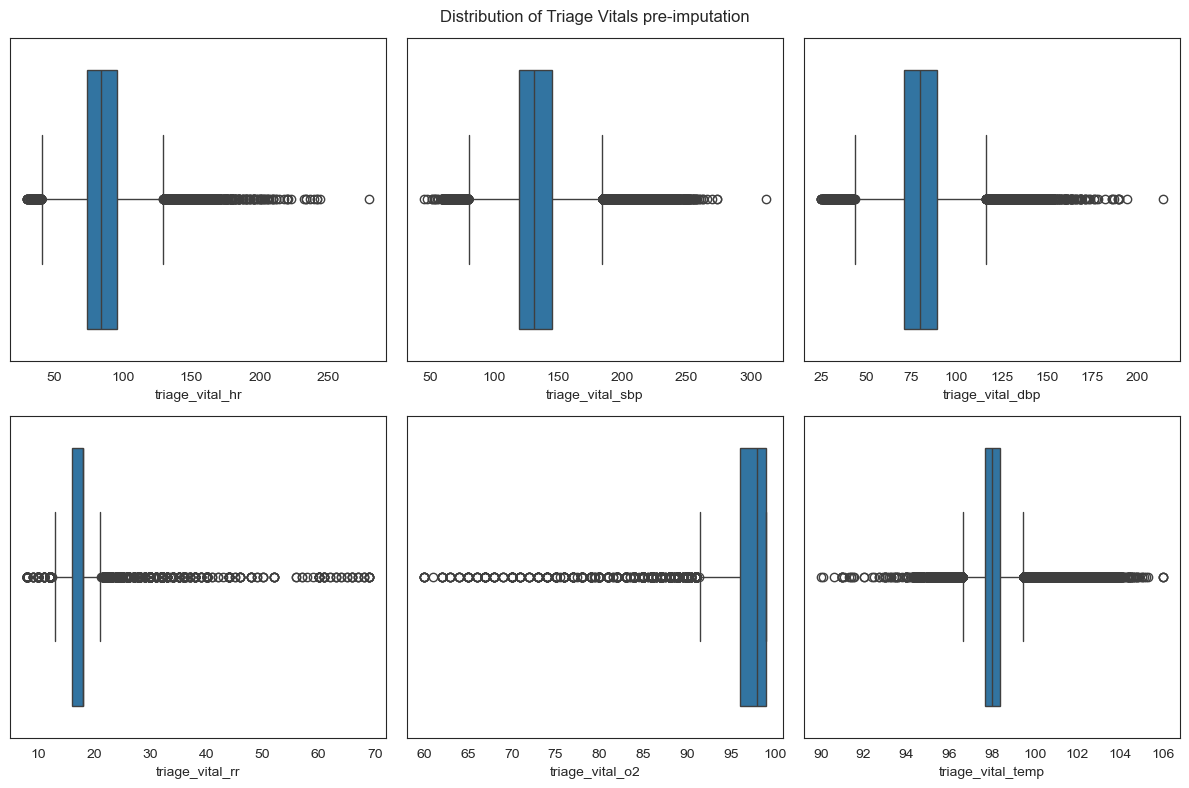

In [ ]:
fig,axes = plt.subplots(2,3, figsize = (12,8))

sns.boxplot(data = triage_df, x = 'triage_vital_hr', ax = axes[0,0])
sns.boxplot(data = triage_df, x = 'triage_vital_sbp', ax = axes[0,1])
sns.boxplot(data = triage_df, x = 'triage_vital_dbp', ax = axes[0,2])
sns.boxplot(data = triage_df, x = 'triage_vital_rr', ax = axes[1,0])
sns.boxplot(data = triage_df, x = 'triage_vital_o2', ax = axes[1,1])
sns.boxplot(data = triage_df, x = 'triage_vital_temp', ax = axes[1,2])

plt.suptitle("Distribution of Triage Vitals pre-imputation")
plt.tight_layout()
plt.show()

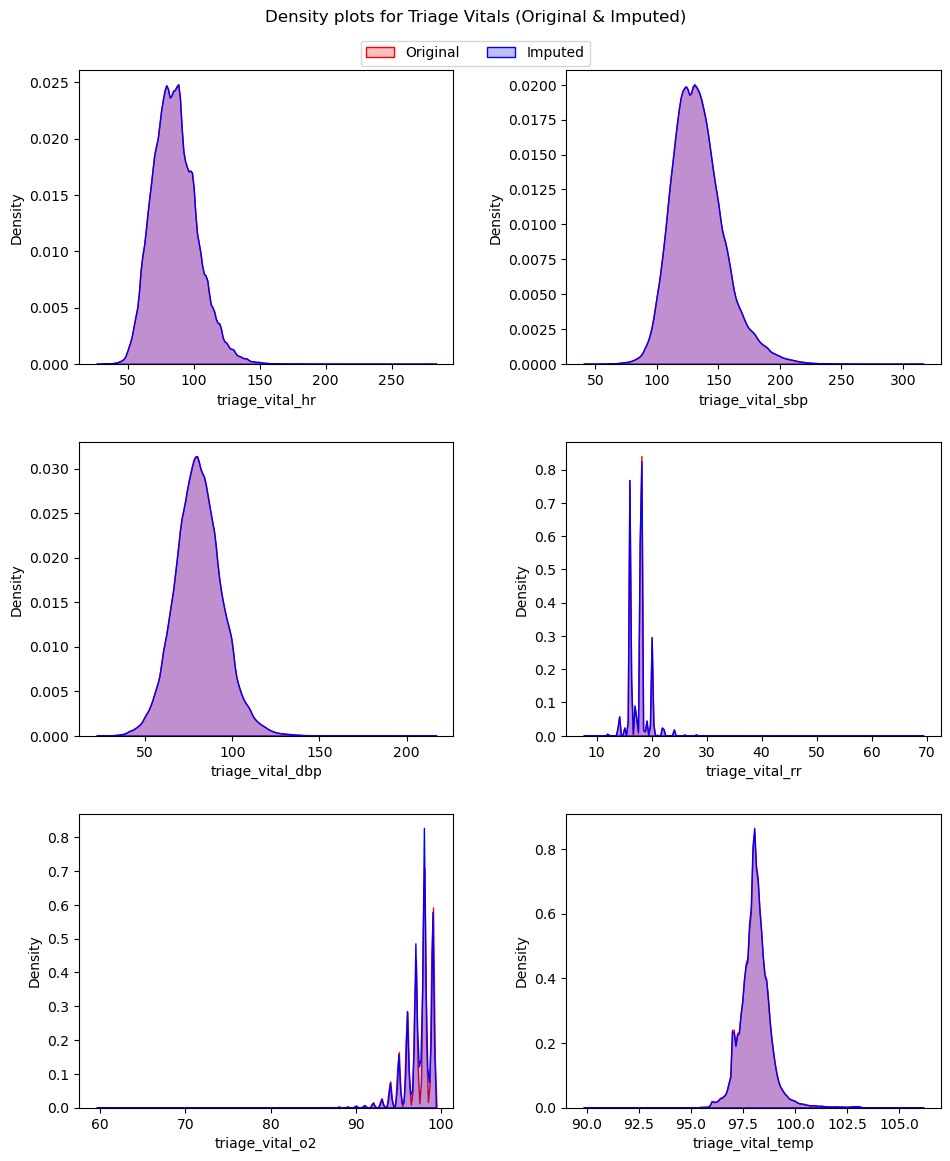

In [20]:
fig,axes = plt.subplots(3,2, figsize = (10,12))

sns.kdeplot(triage_df['triage_vital_hr'], color = 'r', fill = True, label = 'Original', ax = axes[0,0])
sns.kdeplot(triage_df_cleaned['triage_vital_hr'], color = 'b', fill = True, label = 'Imputed', ax = axes[0,0])
sns.kdeplot(triage_df['triage_vital_sbp'], color = 'r', fill = True, label = 'Original', ax = axes[0,1])
sns.kdeplot(triage_df_cleaned['triage_vital_sbp'], color = 'b', fill = True, label = 'Imputed', ax = axes[0,1])
sns.kdeplot(triage_df['triage_vital_dbp'], color = 'r', fill = True, label = 'Original', ax = axes[1,0])
sns.kdeplot(triage_df_cleaned['triage_vital_dbp'], color = 'b', fill = True, label = 'Imputed', ax = axes[1,0])
sns.kdeplot(triage_df['triage_vital_rr'], color = 'r', fill = True, label = 'Original', ax = axes[1,1])
sns.kdeplot(triage_df_cleaned['triage_vital_rr'], color = 'b', fill = True, label = 'Imputed', ax = axes[1,1])
sns.kdeplot(triage_df['triage_vital_o2'], color = 'r', fill = True, label = 'Original', ax = axes[2,0])
sns.kdeplot(triage_df_cleaned['triage_vital_o2'], color = 'b', fill = True, label = 'Imputed', ax = axes[2,0])
sns.kdeplot(triage_df['triage_vital_temp'], color = 'r', fill = True, label = 'Original', ax = axes[2,1])
sns.kdeplot(triage_df_cleaned['triage_vital_temp'], color = 'b', fill = True, label = 'Imputed', ax = axes[2,1])

handles, labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles, labels, loc = 'upper center', 
           ncol = len(handles), bbox_to_anchor=(0.5, 0.96))
plt.suptitle("Density plots for Triage Vitals (Original & Imputed)")
plt.tight_layout(pad =2.5)
plt.show()

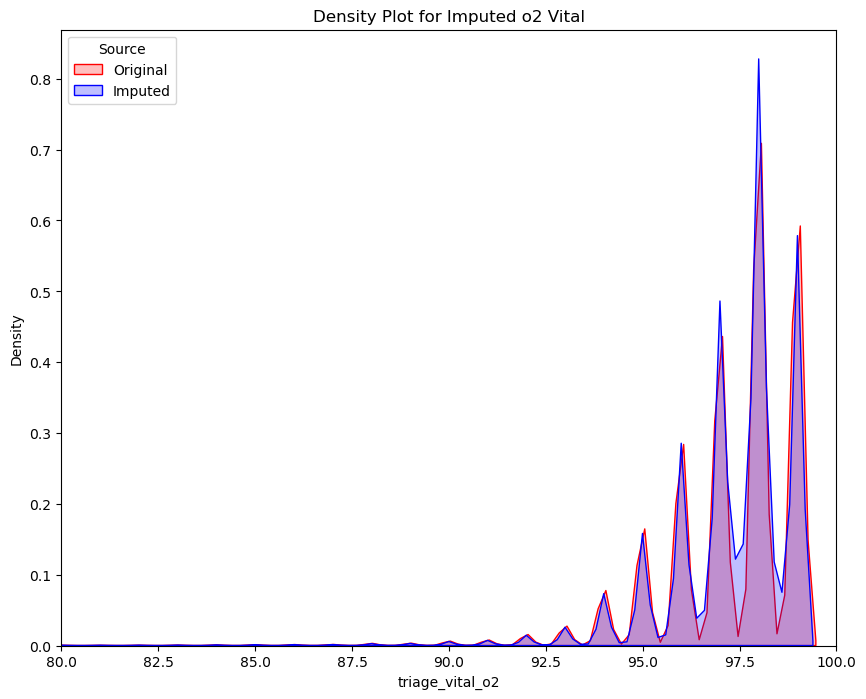

In [24]:
plt.figure(figsize=(10,8))

sns.kdeplot(triage_df['triage_vital_o2'], color = 'r', fill = True, label = 'Original')
sns.kdeplot(triage_df_cleaned['triage_vital_o2'], color = 'b', fill = True, label = 'Imputed')

plt.title("Density Plot for Imputed o2 Vital")
plt.xlim(80,100)
plt.legend(title='Source')

plt.show()

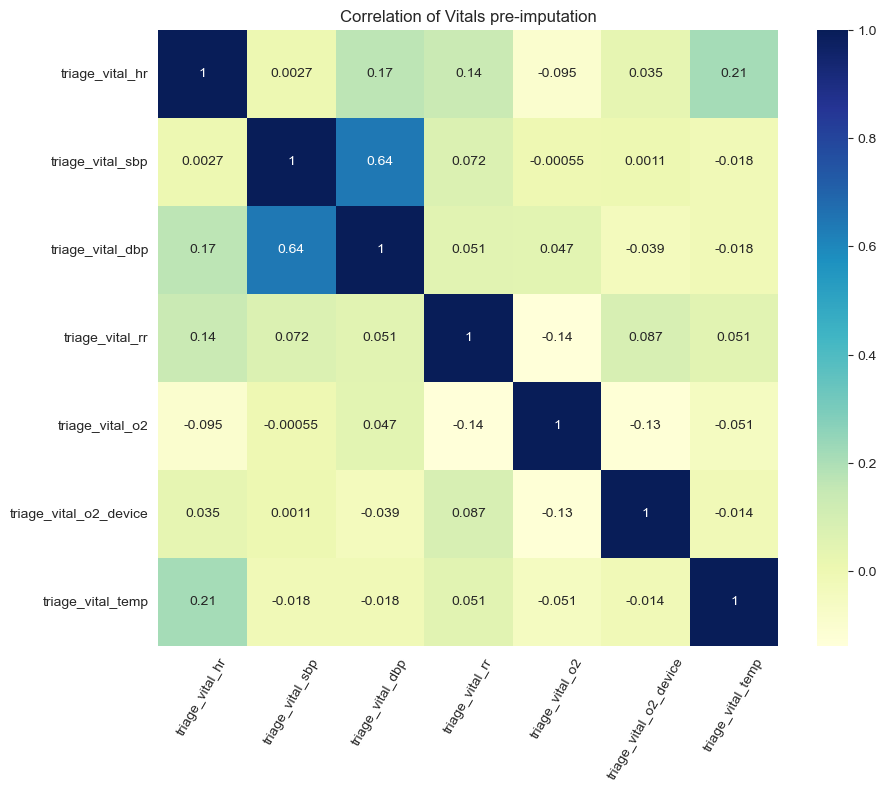

In [ ]:
originalCorr = triage_df[triage_vitals].corr()

plt.figure(figsize=(10,8))

sns.heatmap(data=originalCorr,cmap='YlGnBu', annot = True)
plt.title("Correlation of Vitals pre-imputation")
plt.xticks(rotation=60)
plt.show()

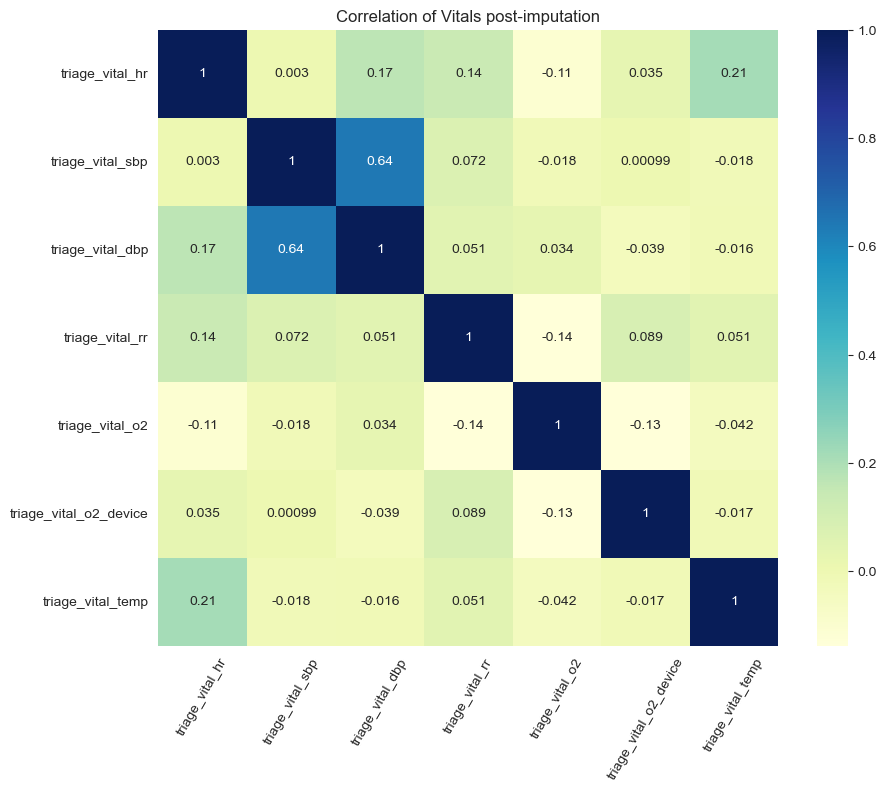

In [ ]:
imputedCorr = triage_df_cleaned[triage_vitals].corr()

plt.figure(figsize=(10,8))

sns.heatmap(data=imputedCorr,cmap='YlGnBu', annot = True)
plt.title("Correlation of Vitals post-imputation")
plt.xticks(rotation=60)
plt.show()

In [ ]:
#recombining the dataframes into one cleaned dataframe

final_df = triage_df.copy()

#overwrite the null vital values with the imputed values
final_df[triage_vitals] = triage_df_cleaned[triage_vitals]
#drop the multi-null vitals rows
final_df = final_df.loc[triage_df_cleaned.index]

In [ ]:
#final check for an Null values

missingCount = final_df.isna().sum()
print(missingCount)


esi                                                   0
age                                                   0
gender                                                0
race                                                  0
arrivalmode                                           0
arrivalmonth                                          0
arrivalday                                            0
arrivalhour_bin                                       0
previousdispo                                         0
pmh_2ndarymalig                                       0
pmh_abdomhernia                                       0
pmh_abdomnlpain                                       0
pmh_abortcompl                                        0
pmh_acqfootdef                                        0
pmh_acrenlfail                                        0
pmh_acutecvd                                          0
pmh_acutemi                                           0
pmh_acutphanm                                   

## 4. Feature Correlation to ESI

In [153]:
#two Correlation matrices need to be created
#first for numerical features
#second for categorical features

#a copy of final_df is made to add categoricals without breaking the original features
#e.g. for PMH a patient can have multiple, which categorically is just  "multiple conditions"
#this cannot be returned to the original feautres using get_dummies().
correlations_df = final_df.copy()

#A numeric version of ESI is created
correlations_df['esi_num'] = pd.to_numeric(correlations_df['esi'])

#past medical history encoded columns replaced with a categorical:
#similar as was done earlier with CC columns
pmh_cols = correlations_df.filter(like="pmh_")

correlations_df['past_m_hist'] = pmh_cols.idxmax(axis=1).str.replace('pmh_','') 
#get col name of true condition
#e.g. the one with value of 1

#calc total number of conditions for each patient
pmh_sums = pmh_cols.sum(axis=1)

#if patient has more than 1 true condition give category "multiple conditions"
correlations_df.loc[pmh_sums > 1, 'past_m_hist'] = 'multiple conditions'

#if sum of all pmh cols is 0, then replace with No PMH
correlations_df.loc[pmh_sums == 0, 'past_m_hist'] = 'No PMH'


#drop numerical pmh columns for the sake of correlation matrix
correlations_df = correlations_df.drop(columns=correlations_df.filter(like="pmh_").columns)

In [154]:
#Numerical Correlation Matrix

num_corr = correlations_df.corr(numeric_only=True)

esi_num_corr = num_corr[['esi_num']].sort_values(by='esi_num', ascending = False)

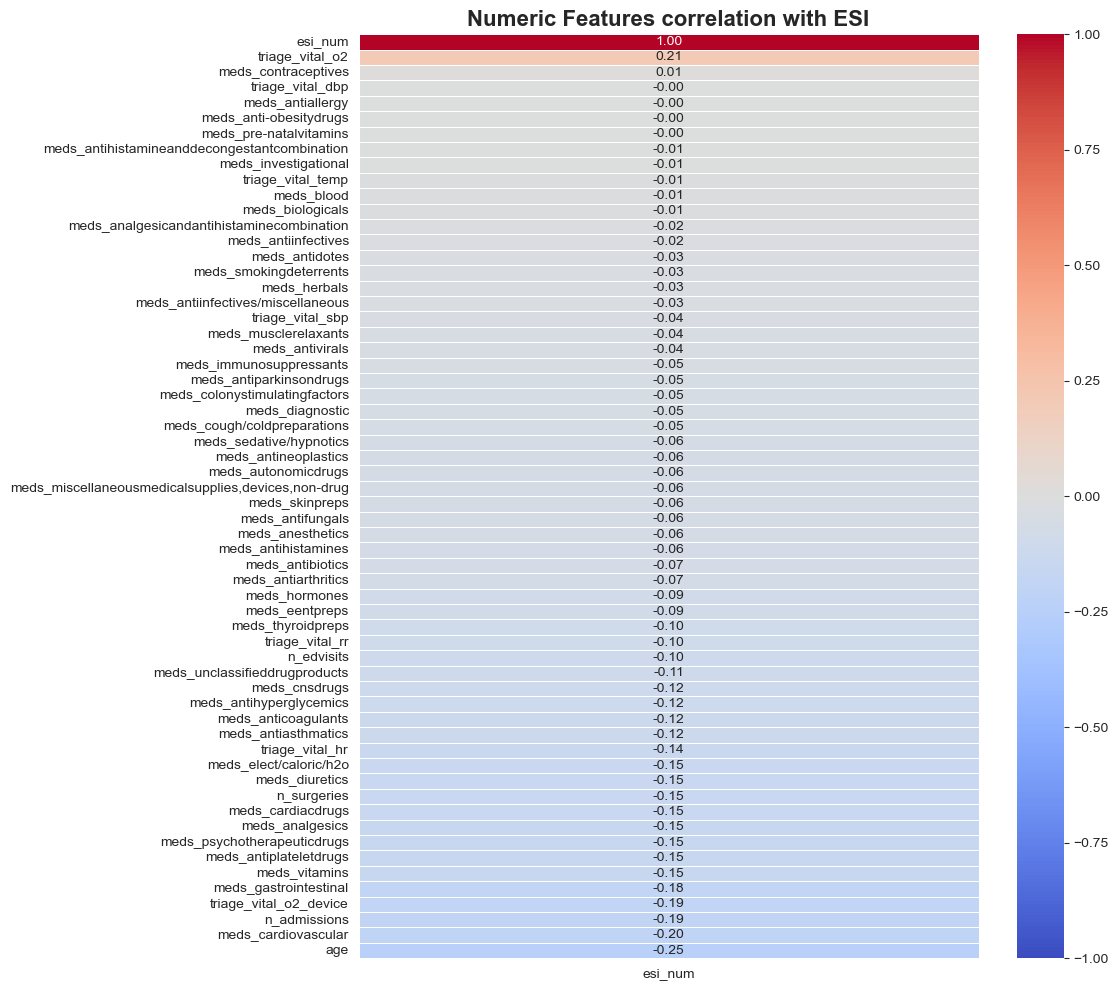

In [155]:
#Plotting the matrix
plt.figure(figsize=(10,12))

sns.heatmap(data=esi_num_corr, 
            cmap='coolwarm', 
            annot = True,
            vmin=-1.0, vmax = 1.0,
            fmt= ".2f",
            linewidths=0.5)

plt.title("Numeric Features correlation with ESI", fontsize=16,
           fontweight = "bold")

plt.show()

As Age increases, Esi score decreases. i.e. older patients are more likely to have more serious ESI scores.

As patient o2 increases, Esi score increases. i.e. the better your o2 stats the more likely you are to be less urgent

Medication features seem to have negligable linear relationship to esi score. 

Grouping medications based on the severity of conditions they treat would reduce feature space and possibly improve correlation to target


In [156]:
#Categorical Correlation Matrix
#calculating correlation between categorical variables and esi
#requires use of Cramer's V and chi-square test

def cramersV(x,y):
    #create a frequency table of x and y
    confusionMatrix = pd.crosstab(x,y)
    #calculate chi-square value
    chi2 = chi2_contingency(confusionMatrix)[0]
    n = confusionMatrix.sum().sum() #total no. of observations
    #calculate phi-square value
    phi2 = chi2 / n
    r, k = confusionMatrix.shape #no. rows (r) and columns (k)
    #apply bias correction 
    #preventing overestimation in small samples
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2) / (n-1)
    kcorr = k - ((k-1)**2) / (n-1)

    #return V value between 0(no correlation) and 1(perfect correlation)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

#select all categorical features
cat_features = correlations_df.select_dtypes(include=['object','category']).columns.tolist()

#dictionary for results
cramers_results = {}

#for each feature: calc the association between it and Esi
for col in cat_features:
    score = cramersV(correlations_df[col], correlations_df['esi'])
    cramers_results[col] = score

#converting dict to a dataframe and ordering
cramers_df = pd.DataFrame.from_dict(cramers_results, orient='index', columns=['Cramers_V'])
cramers_df = cramers_df.sort_values(by='Cramers_V', ascending=False)

#outputting results
print(cramers_df.head(15))

                 Cramers_V
esi               1.000000
chief_complaint   0.490614
arrivalmode       0.221449
ageGroup          0.127488
previousdispo     0.118759
past_m_hist       0.118239
gender            0.103721
race              0.066466
arrivalhour_bin   0.032722
arrivalday        0.018366
arrivalmonth      0.010561


Note: Cramers V scales from 0 (no association) - 1 (perfect association) not -1 to 1.

Arrival hour, day and month seem to have vitually zero impact on esi score. 

Highlights chief_complaint as most important feature

arrivalmode is very meaningful and should be useful for models

pmh,ageGroup previous dispo and gender have fairly weak to moderate association. (agegroup will be removed with just numeric Age being used.)

## 5. Final Dataframe Creation

In [ ]:
#back to using final_df rather than correlation_df
#to include pmh as multiple binary features rather than 1 categorical

#ageGroup, arrivalhour_bin, arrivalday, arrivalmonth, race all need to be dropped
final_df = final_df.drop(columns=['ageGroup','arrivalhour_bin','arrivalday','arrivalmonth','race'])

#Gender can be converted to binary Male = 0, Female = 1
final_df['gender'] = final_df['gender'].map({'Male': 0, 'Female': 1})
final_df['gender'] = final_df['gender'].astype(int)

In [ ]:
#Categorical variables to be dummied:
# arrivalmode, previousdispo
#Chief_complaint stays as categorical to be encoded in model development notebook.

#getting dummies for remaining categorical variables
categorical_cols = ['arrivalmode','previousdispo']
final_df = pd.get_dummies(final_df, columns = categorical_cols, dtype='int')



#arrivalmode features
#new arrivalmode features to be "emergencyServices","wheelchair", "Unassisted", 
#reducing from 7 features to 3
#0 in all features indicates other
final_df.loc[(final_df['arrivalmode_Police'] == 1) | (final_df['arrivalmode_ambulance'] == 1), 'arrivalmode_emergencyservices' ] = 1
#if conditions not true, new col value is null
final_df.loc[(final_df['arrivalmode_Car'] == 1) |
             (final_df['arrivalmode_Public Transport'] == 1) |
             (final_df['arrivalmode_Walk-in'] == 1), 'arrivalmode_unassisted'] = 1

final_df = final_df.drop(columns =['arrivalmode_Police','arrivalmode_ambulance','arrivalmode_Car',
                                   'arrivalmode_Public Transport', 'arrivalmode_Walk-in', 'arrivalmode_Other'])

#Previous Disposition features
#Reduced to just "admit", "discharge", "No previous Disposition"
#'Transfer to another facility','Observe','send to l&d' = admit
#AMA, Eloped, LWBS after / before Triage = discharge
#reducing from 10 features to 3
final_df.loc[(final_df['previousdispo_Transfer to Another Facility'] == 1) | (final_df['previousdispo_Observation'] == 1) |
             (final_df['previousdispo_Send to L&D'] == 1), 'previousdispo_Admit'] = 1

final_df.loc[(final_df['previousdispo_AMA'] == 1) | (final_df['previousdispo_Eloped'] == 1)|
             (final_df['previousdispo_LWBS after Triage'] == 1)| (final_df['previousdispo_LWBS before Triage'] == 1),
             'previousdispo_Discharge'] = 1

unwanted_pDispo_cols =['previousdispo_Transfer to Another Facility',
                       'previousdispo_Observation','previousdispo_Send to L&D',
                       'previousdispo_AMA','previousdispo_Eloped',
                       'previousdispo_LWBS after Triage','previousdispo_LWBS before Triage']
final_df = final_df.drop(columns=unwanted_pDispo_cols)

# meds_ features
#Broken down into 4 categories based on criticality/ seriousness of conditions used for
# higher the category of meds the more likely the patient has serious condition
#reducing from 48 features to 4

meds_tier1 = ['meds_anesthetics','meds_antidotes','meds_anticoagulants',
              'meds_antiplateletdrugs','meds_blood','meds_elect/caloric/h2o',
              'meds_cardiacdrugs'
]
meds_tier2 = ['meds_cardiovascular','meds_antineoplastics','meds_antiparkinsondrugs',
              'meds_immunosuppressants','meds_antihyperglycemics','meds_cnsdrugs','meds_diuretics',
              'meds_psychotherapeuticdrugs','meds_antiinfectives','meds_antiinfectives/miscellaneous',
              'meds_antivirals','meds_antifungals','meds_colonystimulatingfactors','meds_biologicals'
]
meds_tier3 = ['meds_gastrointestinal','meds_analgesics','meds_antiasthmatics',
              'meds_antiarthritics','meds_antibiotics','meds_autonomicdrugs','meds_sedative/hypnotics',
              'meds_musclerelaxants','meds_hormones','meds_thyroidpreps',
              'meds_contraceptives','meds_anti-obesitydrugs'
]
meds_tier4 = ['meds_analgesicandantihistaminecombination','meds_antiallergy',
              'meds_antihistamines','meds_antihistamineanddecongestantcombination',
              'meds_cough/coldpreparations','meds_eentpreps','meds_skinpreps',
              'meds_smokingdeterrents','meds_vitamins','meds_pre-natalvitamins',
              'meds_herbals','meds_diagnostic','meds_investigational'
]
unwanted_meds = ['meds_miscellaneousmedicalsupplies,devices,non-drug',
                 'meds_unclassifieddrugproducts']

final_df['meds_tier1'] = final_df[meds_tier1].sum(axis = 1)
final_df['meds_tier2'] = final_df[meds_tier2].sum(axis = 1)
final_df['meds_tier3'] = final_df[meds_tier3].sum(axis = 1)
final_df['meds_tier4'] = final_df[meds_tier4].sum(axis = 1)

#removing all individual meds features
all_meds_cols = meds_tier1 + meds_tier2 + meds_tier3 + meds_tier4 + unwanted_meds
final_df = final_df.drop(columns= all_meds_cols)

In [159]:
#Replacing arrivalmode nulls with 0 
final_df['arrivalmode_emergencyservices'] = final_df['arrivalmode_emergencyservices'].fillna(value = 0)
final_df['arrivalmode_unassisted'] = final_df['arrivalmode_unassisted'].fillna(value = 0)

In [161]:
#final check of column types
final_df.dtypes

esi                                             category
age                                                int64
gender                                             int64
pmh_2ndarymalig                                  float64
pmh_abdomhernia                                  float64
pmh_abdomnlpain                                  float64
pmh_abortcompl                                   float64
pmh_acqfootdef                                   float64
pmh_acrenlfail                                   float64
pmh_acutecvd                                     float64
pmh_acutemi                                      float64
pmh_acutphanm                                    float64
pmh_adjustmentdisorders                          float64
pmh_adltrespfl                                   float64
pmh_alcoholrelateddisorders                      float64
pmh_allergy                                      float64
pmh_amniosdx                                     float64
pmh_analrectal                 

In [162]:
#check for Null values
missingCount = final_df.isna().sum()
print(missingCount)

esi                                             0
age                                             0
gender                                          0
pmh_2ndarymalig                                 0
pmh_abdomhernia                                 0
pmh_abdomnlpain                                 0
pmh_abortcompl                                  0
pmh_acqfootdef                                  0
pmh_acrenlfail                                  0
pmh_acutecvd                                    0
pmh_acutemi                                     0
pmh_acutphanm                                   0
pmh_adjustmentdisorders                         0
pmh_adltrespfl                                  0
pmh_alcoholrelateddisorders                     0
pmh_allergy                                     0
pmh_amniosdx                                    0
pmh_analrectal                                  0
pmh_anemia                                      0
pmh_aneurysm                                    0


In [163]:
final_df.shape
#305 features

(392413, 305)

In [164]:
#Outputting final dataframe to file to be used in model development
final_df.to_parquet('Data/processed_triage_dataset.parquet', index=False)